# Tongkrongan Hiroo POS — AI Engineering Pipeline v2: Pemodelan Prediksi Penjualan Menu & Generative AI Recommender
**Penanggung Jawab:** Next-Gen AI Engineer | **Tim:** A26-CS011 | **Program:** Asah 2026  
**Input Data:** `menu_daily_reference_hiroo_mapping.csv`, `daily_reference.csv`, `hiroo_product_mapping.csv`, `kpi_reference.json`, `DATA_MENU_HIROO.md`, dan `hiroo_pos_backup_2026-11-21.sql`.  
**Penerima Model:** Tim Fullstack (FS) untuk Dashboard Owner Hiroo melalui API REST / JSON payload.

Notebook Pipeline v2 ini menerapkan pemurnian dataset dan penyelarasan penuh terhadap katalog resmi 63 menu (`MNU-001`–`MNU-063`) serta skema DB POS Fullstack:
1. **Pemurnian Dataset & Strict 1-to-1 Proxy Selection**: Membuang 28 SKU non-F&B/add-on (`Coffee beans`, `Loose Tea`, `Branded`, `Packaged Chocolate`, `Flavours`), lalu memilih **16 SKU F&B representatif 1-to-1** tanpa *bucket size bias* (`data_role = 'external_proxy_not_real_hiroo_sales'`).
2. **Kelengkapan Katalog 63 Menu (`Opsi 1C`)**: Menghasilkan deret waktu sintetis 181 hari (`seed=42`) berlabel transparan (`data_role = 'synthetic_dummy_hiroo_catalog'`) untuk 47 menu tanpa proxy Kaggle agar seluruh 63 menu terlayani penuh oleh model ML tanpa *cold-start fallback*.
3. **Evaluasi Terpisah (*Disaggregated Benchmark*) & Seleksi `MAE (Porsi)` (`Opsi 3B`)**: Melaporkan metrik gabungan (63 menu), subset 16 menu Kaggle riil, dan subset 47 menu sintetis secara terpisah, memilih model terbaik secara programatik berdasarkan `MAE (Porsi)` terendah, serta memvalidasi agregat makro khusus 16 menu Kaggle.
4. **Dual-Key Adapter (`Opsi 4A`) & Gen AI Non-HPP**: Artefak `.joblib` menerima `MNU-001..063`, `menus.code` (`KOP-01..MAK-02`), `menus.id`, maupun alias nama; strategi Gen AI dihitung dinamis dari 16 menu Kaggle riil tanpa klaim margin/HPP fiktif.

---

### Batasan Bisnis & Kepatuhan Playbook Asah 2026 (Wajib Dipatuhi):
1. **Mitra UMKM:** Tongkrongan Hiroo (F&B dengan menu Rp5.000–Rp43.000). Data Kaggle bersifat *external proxy* dan tidak pernah diklaim sebagai transaksi kasir nyata Hiroo.
2. **Bebas API LLM / AutoML Kotak Hitam:** Peramalan kuantitatif menggunakan model statistika dan machine learning terlatih (`Baseline 7-day MA`, `Ridge`, `Random Forest`, `Gradient Boosting`).
3. **Transparansi Lineage & Anti-Leakage:** Setiap baris membawa `data_role`, seluruh fitur lag/rolling memakai `.groupby('hiroo_menu').shift(1)`, dan split Train/Test bersifat kronologis murni (`80/20`).
4. **Tanpa Klaim HPP/Margin & Mata Uang Tidak Terkonfirmasi:** Tidak memberi simbol `Rp` pada `sales_value` Kaggle dan tidak mengklaim margin/HPP karena DB POS tidak memiliki kolom modal/BOM.

## 1. Setup Lingkungan, Dependensi, dan Konfigurasi Direktori
Menyelaraskan direktori kerja `hiroo_ae_playground` (mendukung eksekusi lokal maupun Google Colab), memuat pustaka saintifik, serta mengatur opsi visualisasi.

In [1]:
from pathlib import Path
import re
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

# Konfigurasi Path Ruang Kerja (Lokal + Opsional Fallback Colab)
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
if not (ROOT / 'data').exists():
    colab_candidates = [
        Path('/content/tongkrongan-hiroo/hiroo_ae_playground'),
        Path('/content/drive/MyDrive/tongkrongan-hiroo/hiroo_ae_playground'),
        Path('/content/hiroo_ae_playground'),
    ]
    for cand in colab_candidates:
        if (cand / 'data').exists():
            ROOT = cand
            break

assert (ROOT / 'data').exists(), 'Pastikan notebook dijalankan dari hiroo_ae_playground.'

DATA_DIR = ROOT / 'data'
DOCS_DIR = ROOT / 'docs'
OUTPUTS_DIR = ROOT / 'outputs'
OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option('display.max_columns', 40)
pd.set_option('display.max_colwidth', 90)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (11, 4.5)
plt.rcParams['font.size'] = 10

print("PASS: Lingkungan AI Engineering v2 siap digunakan.")
print(f"Direktori Kerja : {ROOT}")
print(f"Direktori Output: {OUTPUTS_DIR}")

PASS: Lingkungan AI Engineering v2 siap digunakan.
Direktori Kerja : C:\Users\rilob\BELAJAR PROGRAMMING\Asah Dicoding 2026\tongkrongan-hiroo\hiroo_ae_playground
Direktori Output: C:\Users\rilob\BELAJAR PROGRAMMING\Asah Dicoding 2026\tongkrongan-hiroo\hiroo_ae_playground\outputs


## 2. Pemuatan Data Handoff Data Science, Parser Katalog Resmi 63 Menu, & Dual-Key Adapter DB FS
Memuat dataset olahan DS (`menu_daily_reference_hiroo_mapping.csv`, `daily_reference.csv`, `hiroo_product_mapping.csv`, `kpi_reference.json`), mem-parse seluruh 63 menu resmi dari `DATA_MENU_HIROO.md` Bagian 3 + komposisi paket Bagian 2G, serta membaca skema & 13 menu seed dari `hiroo_pos_backup_2026-11-21.sql` untuk membangun **Dual-Key Adapter (Opsi 4A)**.

In [2]:
# 1. Pemuatan Dataset Referensi DS
df_menu_daily = pd.read_csv(DATA_DIR / 'menu_daily_reference_hiroo_mapping.csv')
df_daily = pd.read_csv(DATA_DIR / 'daily_reference.csv')
df_prod_map = pd.read_csv(DATA_DIR / 'hiroo_product_mapping.csv')
df_menu_ref = pd.read_csv(DATA_DIR / 'menu_reference_hiroo_mapping.csv')

with open(ROOT / 'kpi_reference.json', 'r', encoding='utf-8') as f:
    kpi_meta = json.load(f)

df_menu_daily['transaction_date'] = pd.to_datetime(df_menu_daily['transaction_date'])
df_daily['transaction_date'] = pd.to_datetime(df_daily['transaction_date'])

# 2. Parser Katalog Resmi DATA_MENU_HIROO.md (Bagian 3: MNU-001 s/d MNU-063 + Bagian 2G Komposisi Bundling)
menu_md_text = (DOCS_DIR / 'DATA_MENU_HIROO.md').read_text(encoding='utf-8')

master_rows = re.findall(
    r'\|\s*`(MNU-\d{3})`\s*\|\s*([^|]+?)\s*\|\s*([^|]+?)\s*\|\s*(\d+)\s*\|',
    menu_md_text
)
assert len(master_rows) == 63, f"Harusnya 63 menu di Bagian 3 DATA_MENU_HIROO.md, ditemukan {len(master_rows)}"

# Parse komposisi paket Bagian 2G (baris 122-126)
bundle_comp_rows = re.findall(
    r'\|\s*\d+\s*\|\s*([^|]+?)\s*\|\s*\d+K\s*\|\s*Rp[\d.]+\s*\|\s*([^|]+?)\s*\|',
    menu_md_text.split('### G. Republik Hiroo')[1].split('## 3. Tabel Induk')[0]
)
bundle_comp_by_name = {}
for b_name, b_comp in bundle_comp_rows:
    b_name_clean = b_name.strip()
    if b_name_clean == 'Dimsum':
        bundle_comp_by_name['Otak-otak / Dimsum'] = b_comp.strip()
    else:
        bundle_comp_by_name[b_name_clean] = b_comp.strip()

# Pemetaan 7 kategori resmi -> 4 enum kategori DB FS: enum('Kopi','Non-Kopi','Makanan','Cemilan')
def map_to_fs_category(menu_name, official_cat):
    if official_cat == 'Ice Coffee':
        return 'Kopi'
    if official_cat == 'Minuman Dingin':
        return 'Non-Kopi'
    if official_cat == 'Minuman HOT':
        return 'Kopi' if menu_name in ['Kopi Hitam', 'Kopi Susu', 'Coffee Brown'] else 'Non-Kopi'
    if official_cat == 'Hiroo Premium':
        return 'Kopi' if ('Coffee' in menu_name or 'Affogato' in menu_name) else 'Non-Kopi'
    if official_cat == 'Makanan Ringan':
        return 'Cemilan'
    if official_cat == 'Makanan':
        return 'Makanan'
    if official_cat == 'Republik Hiroo':
        return 'Cemilan'
    return 'Non-Kopi'

catalog_records = []
for menu_id, menu_name, category, price_str in master_rows:
    m_name = menu_name.strip()
    m_cat = category.strip()
    is_bundle = (m_cat == 'Republik Hiroo')
    catalog_records.append({
        'menu_id': menu_id.strip(),
        'menu_name': m_name,
        'category': m_cat,
        'price_idr': int(price_str),
        'is_bundle': is_bundle,
        'bundle_composition': bundle_comp_by_name.get(m_name, ''),
        'fs_category_4enum': map_to_fs_category(m_name, m_cat),
        'name_alias': 'Dimsum' if m_name == 'Otak-otak / Dimsum' else ''
    })

catalog_df = pd.DataFrame(catalog_records)
assert len(catalog_df) == 63 and catalog_df['menu_id'].nunique() == 63

# 3. Parser Skema & 13 Seed Menu DB Fullstack (hiroo_pos_backup_2026-11-21.sql)
sql_text = (DATA_DIR / 'database' / 'hiroo_pos_backup_2026-11-21.sql').read_text(encoding='utf-8')
fs_seed_matches = re.findall(
    r"\((\d+),'([A-Z]+-\d+)','([^']+)','([^']+)',([\d.]+),'([^']*)'",
    sql_text
)
assert len(fs_seed_matches) == 13, f"Harusnya 13 menu seed di SQL backup, ditemukan {len(fs_seed_matches)}"

# Pemetaan 13 seed DB FS -> Katalog Resmi 63 Menu (Opsi 4A Dual-Key Adapter)
FS_TO_MNU_ALIGNMENT = {
    'KOP-01': ('MNU-026', 'direct_semantic_match_price_diff', 'Es Kopi Susu Hiroo (Rp18k) -> Ice Coffee Milk Hiroo (Rp15k)'),
    'KOP-02': ('MNU-017', 'legacy_seed_closest_proxy_unaligned', 'Americano Dingin (Rp15k) tidak ada di 63 menu; diproksikan ke MNU-017 Kopi Hitam'),
    'KOP-03': ('MNU-019', 'legacy_seed_closest_proxy_unaligned', 'Cafe Latte Hangat (Rp20k) tidak ada di 63 menu; diproksikan ke MNU-019 Kopi Susu'),
    'KOP-04': ('MNU-025', 'legacy_seed_closest_proxy_unaligned', 'Kopi Tubruk Gula Aren (Rp12k) tidak ada di 63 menu; diproksikan ke MNU-025 Coffee Brown Sugar'),
    'NON-01': ('MNU-011', 'direct_semantic_match_price_diff', 'Matcha Latte Hijau (Rp22k) -> Matcha Latte (Rp15k)'),
    'NON-02': ('MNU-004', 'direct_semantic_match_price_diff', 'Es Lemon Tea Segar (Rp12k) -> Es Lemon Tea (Rp10k)'),
    'NON-03': ('MNU-001', 'direct_semantic_match_price_diff', 'Es Teh Manis (Rp8k) -> Es Teh (Rp6k)'),
    'NON-04': ('MNU-015', 'direct_semantic_match_price_diff', 'Air Mineral 600ml (Rp5k) -> Air Mineral (Rp7k)'),
    'CEM-01': ('MNU-041', 'legacy_seed_closest_proxy_unaligned', 'Pisang Goreng Aren (Rp15k) tidak ada di 63 menu; diproksikan ke MNU-041 Tempe Mendoan'),
    'CEM-02': ('MNU-038', 'direct_semantic_match_price_diff', 'Kentang Goreng (Rp16k) -> French Fries (Rp10k)'),
    'CEM-03': ('MNU-048', 'legacy_seed_closest_proxy_unaligned', 'Roti Bakar Cokelat Keju (Rp18k) tidak ada di 63 menu; diproksikan ke MNU-048 Roti Separuh Matcha Cheese'),
    'MAK-01': ('MNU-056', 'direct_semantic_match_price_diff', 'Mie Goreng Spesial Hiroo (Rp22k) -> Mie Goreng + Telur (Rp13k)'),
    'MAK-02': ('MNU-058', 'legacy_seed_closest_proxy_unaligned', 'Nasi Ayam Katsu Sambal (Rp25k) tidak ada di 63 menu; diproksikan ke MNU-058 Ayam Penyet (Rp28k)'),
}

mnu_to_name = dict(zip(catalog_df['menu_id'], catalog_df['menu_name']))
mnu_to_price = dict(zip(catalog_df['menu_id'], catalog_df['price_idr']))

fs_seed_rows = []
fs_code_by_mnu = {}
fs_id_by_mnu = {}
for fs_id_s, fs_code, fs_name, fs_cat, fs_price_s, fs_serving in fs_seed_matches:
    fs_id = int(fs_id_s)
    target_mnu, align_status, align_note = FS_TO_MNU_ALIGNMENT[fs_code]
    fs_code_by_mnu[target_mnu] = fs_code
    fs_id_by_mnu[target_mnu] = fs_id
    fs_seed_rows.append({
        'fs_menu_id': fs_id,
        'fs_code': fs_code,
        'fs_name': fs_name,
        'fs_category_enum': fs_cat,
        'fs_price_idr': int(float(fs_price_s)),
        'target_menu_id': target_mnu,
        'target_menu_name': mnu_to_name[target_mnu],
        'official_price_idr': mnu_to_price[target_mnu],
        'fs_seed_alignment': align_status,
        'alignment_note': align_note
    })

fs_seed_alignment_df = pd.DataFrame(fs_seed_rows)
catalog_df['fs_code_alias'] = catalog_df['menu_id'].map(fs_code_by_mnu).fillna('')
catalog_df['fs_menu_id_alias'] = catalog_df['menu_id'].map(fs_id_by_mnu)

# Konstruksi Tabel Kamus Dual-Key Adapter (Opsi 4A)
dual_key_adapter = {}
for _, row in catalog_df.iterrows():
    payload_ref = {
        'menu_id': row['menu_id'],
        'menu_name': row['menu_name'],
        'category': row['category'],
        'fs_category_4enum': row['fs_category_4enum'],
        'price_idr': int(row['price_idr']),
        'is_bundle': bool(row['is_bundle']),
        'bundle_composition': row['bundle_composition'],
        'fs_seed_alignment': 'canonical_63_menu_catalog'
    }
    dual_key_adapter[row['menu_id'].upper()] = payload_ref
    dual_key_adapter[row['menu_name'].lower()] = payload_ref
    if row['name_alias']:
        dual_key_adapter[row['name_alias'].lower()] = {**payload_ref, 'matched_via': f"alias:{row['name_alias']}"}

# Legacy alias ejaan DS CSV & variasi penulisan
legacy_aliases = {
    'coffee milk hiroo': ('MNU-026', 'legacy_ds_csv_spelling'),
    'choco malt': ('MNU-008', 'legacy_ds_csv_case_variant'),
    'sayap-sayap patah hiroo': ('MNU-053', 'hyphen_spacing_variant'),
    'dimsum': ('MNU-063', 'section_2g_short_name'),
}
for alias_k, (target_mnu, align_tag) in legacy_aliases.items():
    base_ref = dict(dual_key_adapter[target_mnu])
    base_ref['fs_seed_alignment'] = align_tag
    dual_key_adapter[alias_k.lower()] = base_ref

# Tambahkan seluruh 13 DB FS id, code, dan name
for _, frow in fs_seed_alignment_df.iterrows():
    base_ref = dict(dual_key_adapter[frow['target_menu_id']])
    fs_ref = {
        **base_ref,
        'fs_menu_id': int(frow['fs_menu_id']),
        'fs_code': frow['fs_code'],
        'fs_name': frow['fs_name'],
        'fs_price_idr': int(frow['fs_price_idr']),
        'fs_seed_alignment': frow['fs_seed_alignment'],
        'alignment_note': frow['alignment_note']
    }
    dual_key_adapter[frow['fs_code'].upper()] = fs_ref
    dual_key_adapter[frow['fs_name'].lower()] = fs_ref
    dual_key_adapter[str(int(frow['fs_menu_id']))] = fs_ref

print(f"menu_daily_reference_hiroo_mapping : {df_menu_daily.shape[0]:,} baris, {df_menu_daily['product_id'].nunique()} SKU unik")
print(f"daily_reference                    : {df_daily.shape[0]} hari ({df_daily['transaction_date'].min().date()} s/d {df_daily['transaction_date'].max().date()})")
print(f"catalog_df (DATA_MENU_HIROO.md)    : {len(catalog_df)} menu resmi across {catalog_df['category'].nunique()} kategori")
print(f"fs_seed_alignment_df (SQL backup)  : {len(fs_seed_alignment_df)} menu seed DB FS (7 direct, 6 proxy unaligned)")

print("\n--- Preview Katalog Resmi (5 Baris Pertama + 5 Paket Republik Hiroo) ---")
display(pd.concat([catalog_df.head(5), catalog_df[catalog_df['is_bundle']]]))

print("\n--- Penyelarasan 13 Seed DB FS (hiroo_pos_backup_2026-11-21.sql) vs Katalog 63 Menu ---")
display(fs_seed_alignment_df[['fs_menu_id', 'fs_code', 'fs_name', 'fs_category_enum', 'fs_price_idr', 'target_menu_id', 'target_menu_name', 'official_price_idr', 'fs_seed_alignment']])

menu_daily_reference_hiroo_mapping : 12,132 baris, 80 SKU unik
daily_reference                    : 181 hari (2023-01-01 s/d 2023-06-30)
catalog_df (DATA_MENU_HIROO.md)    : 63 menu resmi across 7 kategori
fs_seed_alignment_df (SQL backup)  : 13 menu seed DB FS (7 direct, 6 proxy unaligned)

--- Preview Katalog Resmi (5 Baris Pertama + 5 Paket Republik Hiroo) ---


,menu_id,menu_name,category,price_idr,is_bundle,bundle_composition,fs_category_4enum,name_alias,fs_code_alias,fs_menu_id_alias
0,MNU-001,Es Teh,Minuman Dingin,6000,False,,Non-Kopi,,NON-03,7.0
1,MNU-002,Es Susu,Minuman Dingin,8000,False,,Non-Kopi,,,NaN
2,MNU-003,Es Teh Tarik,Minuman Dingin,10000,False,,Non-Kopi,,,NaN
3,MNU-004,Es Lemon Tea,Minuman Dingin,10000,False,,Non-Kopi,,NON-02,6.0
4,MNU-005,Josua,Minuman Dingin,10000,False,,Non-Kopi,,,NaN
58,MNU-059,Roti Picisan Hiroo + Hazelnut Latte,Republik Hiroo,35000,True,Roti Picisan (20K) + Hazelnut Latte (15K),Cemilan,,,NaN
59,MNU-060,Sayap-sayap Patah Hiroo + Iced Rosela Hati Hiroo,Republik Hiroo,43000,True,Sayap-Sayap Patah (25K) + Rosela Hati (20K),Cemilan,,,NaN
60,MNU-061,Kentang Mozzarella + Matcha Aren Hiroo,Republik Hiroo,35000,True,Kentang Mozzarella (20K) + Matcha Aren (18K),Cemilan,,,NaN
61,MNU-062,Chicken Pop + Manggo Cili,Republik Hiroo,30000,True,Chicken Pop (20K) + Minuman Manggo Cili,Cemilan,,,NaN
62,MNU-063,Otak-otak / Dimsum,Republik Hiroo,30000,True,Menu cemilan paket dimsum/otak-otak,Cemilan,Dimsum,,NaN



--- Penyelarasan 13 Seed DB FS (hiroo_pos_backup_2026-11-21.sql) vs Katalog 63 Menu ---


,fs_menu_id,fs_code,fs_name,fs_category_enum,fs_price_idr,target_menu_id,target_menu_name,official_price_idr,fs_seed_alignment
0,1,KOP-01,Es Kopi Susu Hiroo,Kopi,18000,MNU-026,Ice Coffee Milk Hiroo,15000,direct_semantic_match_price_diff
1,2,KOP-02,Americano Dingin,Kopi,15000,MNU-017,Kopi Hitam,6000,legacy_seed_closest_proxy_unaligned
2,3,KOP-03,Cafe Latte Hangat,Kopi,20000,MNU-019,Kopi Susu,8000,legacy_seed_closest_proxy_unaligned
3,4,KOP-04,Kopi Tubruk Gula Aren,Kopi,12000,MNU-025,Coffee Brown Sugar,15000,legacy_seed_closest_proxy_unaligned
4,5,NON-01,Matcha Latte Hijau,Non-Kopi,22000,MNU-011,Matcha Latte,15000,direct_semantic_match_price_diff
5,6,NON-02,Es Lemon Tea Segar,Non-Kopi,12000,MNU-004,Es Lemon Tea,10000,direct_semantic_match_price_diff
6,7,NON-03,Es Teh Manis,Non-Kopi,8000,MNU-001,Es Teh,6000,direct_semantic_match_price_diff
7,8,NON-04,Air Mineral 600ml,Non-Kopi,5000,MNU-015,Air Mineral,7000,direct_semantic_match_price_diff
8,9,CEM-01,Pisang Goreng Aren,Cemilan,15000,MNU-041,Tempe Mendoan,10000,legacy_seed_closest_proxy_unaligned
9,10,CEM-02,Kentang Goreng,Cemilan,16000,MNU-038,French Fries,10000,direct_semantic_match_price_diff


## 3. Kondisi *BEFORE* Pemurnian: Audit Dataset Referensi DS & Celah Kategori Non-F&B
Menampilkan secara eksplisit kondisi data mentah **sebelum (*BEFORE*)** pemurnian F&B dan seleksi *Strict 1-to-1*: total `12.132` baris, `80` SKU di 9 kategori Kaggle (termasuk `28` SKU non-F&B / *add-on* sirup yang harus di-drop), serta status awal pemetaan DS (`74` unmapped, `6` baris resmi pada 3 pasangan menu).

In [3]:
DROP_CATEGORIES = ['Coffee beans', 'Loose Tea', 'Branded', 'Packaged Chocolate', 'Flavours']

# Ringkasan BEFORE: dataset mentah menu_daily_reference_hiroo_mapping.csv
before_raw_summary = pd.DataFrame([{
    'Tahap': 'BEFORE (Raw DS Handoff)',
    'Jumlah SKU Unik': int(df_menu_daily['product_id'].nunique()),
    'Jumlah Kategori Kaggle': int(df_prod_map['product_category'].nunique()),
    'Jumlah Baris Harian': int(len(df_menu_daily)),
    'Total Units Sold': int(df_menu_daily['units_sold'].sum()),
    'Total Sales Value (Unconfirmed Currency)': round(float(df_menu_daily['sales_value'].sum()), 2),
    'Menu Hiroo Terpetakan DS': int(df_prod_map[df_prod_map['mapping_type'] != 'unmapped']['hiroo_menu_name'].nunique())
}])
print("=== [BEFORE] Ringkasan Dataset Mentah DS ===")
display(before_raw_summary)

print("=== [BEFORE] Sampel 5 Baris Mentah menu_daily_reference_hiroo_mapping.csv ===")
display(df_menu_daily.head(5))

# Breakdown 9 Kategori Kaggle (28 Drop vs 52 F&B Keep)
sku_stats = df_menu_daily.groupby('product_id', as_index=False).agg(
    row_count=('transaction_date', 'count'),
    total_units=('units_sold', 'sum')
)
df_prod_before = df_prod_map.merge(sku_stats, on='product_id', how='left')
df_prod_before['v2_filter_decision'] = np.where(
    df_prod_before['product_category'].isin(DROP_CATEGORIES),
    'DROP (Non-F&B / Add-on)',
    'KEEP (Kandidat F&B Murni)'
)

cat_breakdown_before = df_prod_before.groupby(['v2_filter_decision', 'product_category'], as_index=False).agg(
    jumlah_sku=('product_id', 'count'),
    jumlah_baris_harian=('row_count', 'sum'),
    total_units_sold=('total_units', 'sum')
).sort_values(['v2_filter_decision', 'jumlah_sku'], ascending=[True, False])

print("=== [BEFORE] Breakdown 9 Kategori Kaggle (28 SKU Drop vs 52 SKU Kandidat F&B) ===")
display(cat_breakdown_before)

print("=== [BEFORE] 6 Baris Pemetaan Resmi DS Awal (hiroo_product_mapping.csv) ===")
display(df_prod_map[df_prod_map['mapping_type'] != 'unmapped'][['product_id', 'product_detail', 'product_category', 'hiroo_menu_name', 'mapping_type', 'mapping_reason']])

=== [BEFORE] Ringkasan Dataset Mentah DS ===


,Tahap,Jumlah SKU Unik,Jumlah Kategori Kaggle,Jumlah Baris Harian,Total Units Sold,Total Sales Value (Unconfirmed Currency),Menu Hiroo Terpetakan DS
0,BEFORE (Raw DS Handoff),80,9,12132,214470,698812.33,3


=== [BEFORE] Sampel 5 Baris Mentah menu_daily_reference_hiroo_mapping.csv ===


,transaction_date,product_id,product_detail,units_sold,sales_value,hiroo_menu_name,mapping_type,mapping_reason,data_role
0,2023-01-01,22,Our Old Time Diner Blend Sm,15,30.0,NaN,unmapped,Tidak ditemukan padanan produk yang cukup spesifik pada foto menu Hiroo.,external_proxy_not_real_hiroo_sales
1,2023-01-01,23,Our Old Time Diner Blend Rg,21,52.5,NaN,unmapped,Tidak ditemukan padanan produk yang cukup spesifik pada foto menu Hiroo.,external_proxy_not_real_hiroo_sales
2,2023-01-01,24,Our Old Time Diner Blend Lg,18,54.0,NaN,unmapped,Tidak ditemukan padanan produk yang cukup spesifik pada foto menu Hiroo.,external_proxy_not_real_hiroo_sales
3,2023-01-01,25,Brazilian Sm,23,50.6,NaN,unmapped,Tidak ditemukan padanan produk yang cukup spesifik pada foto menu Hiroo.,external_proxy_not_real_hiroo_sales
4,2023-01-01,26,Brazilian Rg,14,42.0,NaN,unmapped,Tidak ditemukan padanan produk yang cukup spesifik pada foto menu Hiroo.,external_proxy_not_real_hiroo_sales


=== [BEFORE] Breakdown 9 Kategori Kaggle (28 SKU Drop vs 52 SKU Kandidat F&B) ===


,v2_filter_decision,product_category,jumlah_sku,jumlah_baris_harian,total_units_sold
1,DROP (Non-F&B / Add-on),Coffee beans,10,966,1828
3,DROP (Non-F&B / Add-on),Loose Tea,8,680,1210
2,DROP (Non-F&B / Add-on),Flavours,4,530,10511
0,DROP (Non-F&B / Add-on),Branded,3,289,776
4,DROP (Non-F&B / Add-on),Packaged Chocolate,3,262,487
6,KEEP (Kandidat F&B Murni),Coffee,21,3794,89250
8,KEEP (Kandidat F&B Murni),Tea,16,2896,69737
5,KEEP (Kandidat F&B Murni),Bakery,11,1991,23214
7,KEEP (Kandidat F&B Murni),Drinking Chocolate,4,724,17457


=== [BEFORE] 6 Baris Pemetaan Resmi DS Awal (hiroo_product_mapping.csv) ===


,product_id,product_detail,product_category,hiroo_menu_name,mapping_type,mapping_reason
37,38,Latte,Coffee,Coffee Milk Hiroo,proxy,"Latte sejenis kopi susu, tetapi rasa dan pola permintaan tidak identik."
38,39,Latte Rg,Coffee,Coffee Milk Hiroo,proxy,Latte ukuran regular; ukuran menu Hiroo tidak dirinci.
39,40,Cappuccino,Coffee,Cappucino Hiroo,near_equivalent,Cappuccino sesuai jenis menu; ejaan menu Hiroo mengikuti foto.
40,41,Cappuccino Lg,Coffee,Cappucino Hiroo,near_equivalent,Cappuccino ukuran large; ukuran menu Hiroo tidak dirinci.
57,58,Dark chocolate Rg,Drinking Chocolate,Choco malt,proxy,Minuman cokelat panas dibandingkan minuman cokelat Hiroo; penyajian mungkin berbeda.
58,59,Dark chocolate Lg,Drinking Chocolate,Choco malt,proxy,Minuman cokelat panas ukuran large; tidak ada padanan ukuran.


## 4. Pemurnian F&B, *Strict 1-to-1 Proxy Selection*, & Generasi Dummy Terlabel (`Opsi 1C`) + Perbandingan *Before–After*
Menerapkan 3 tahap transformasi v2:
1. **Stage 1 (Drop 28 SKU Non-F&B & `Flavours`)**: Membuang `Coffee beans` (10), `Loose Tea` (8), `Branded` (3), `Packaged Chocolate` (3), dan `Flavours` (4) $\to$ tersisa **52 SKU F&B siap saji** (`9.405` baris).
2. **Stage 2 (*Strict 1-to-1 Selection*)**: Memilih tepat **16 pasangan SKU $\leftrightarrow$ menu resmi** tanpa `groupby().sum()` sehingga 100% bebas *bucket size bias*, menormalisasi ejaan ke `DATA_MENU_HIROO.md`, menandai `data_role = 'external_proxy_not_real_hiroo_sales'`, dan mengekspor audit 80 SKU ke `outputs/ae_product_mapping_audit.csv`.
3. **Stage 3 (Generasi Dummy Terlabel `Opsi 1C`)**: Menyintesis seri 181 hari (`seed=42`) untuk 47 menu katalog tersisa memakai rumus terdokumentasi (`category_prior` konservatif untuk paket `Republik Hiroo` $\times$ `dow_index` $\times$ faktor tren bulanan `daily_reference.csv` + noise stokastik terkendali), berlabel `data_role = 'synthetic_dummy_hiroo_catalog'`, dan mengekspor `outputs/ae_catalog_lineage_audit.csv`.

In [4]:
# --- STAGE 1: Drop 28 SKU Non-F&B & Flavours ---
df_fnb_map = df_prod_map[~df_prod_map['product_category'].isin(DROP_CATEGORIES)].copy()
df_fnb_daily = df_menu_daily[df_menu_daily['product_id'].isin(df_fnb_map['product_id'])].copy()
assert df_fnb_map['product_id'].nunique() == 52
assert len(df_fnb_daily) == 9405

# --- STAGE 2: Strict 1-to-1 Representative Proxy Selection (16 Pasangan Baku) ---
STRICT_1TO1_MAP = {
    38: ('Ice Coffee Milk Hiroo', 'DS Official (normalized spelling)', 'proxy',
         'DS official proxy Latte -> MNU-026 Ice Coffee Milk Hiroo; varian size pid 39 didrop untuk mencegah bucket size bias.'),
    40: ('Cappucino Hiroo', 'DS Official', 'near_equivalent',
         'DS official near_equivalent Cappuccino -> MNU-030 Cappucino Hiroo; varian size pid 41 didrop untuk mencegah bucket size bias.'),
    58: ('Choco Malt', 'DS Official (normalized capitalization)', 'proxy',
         'DS official proxy Dark chocolate Rg -> MNU-008 Choco Malt; varian size pid 59 didrop untuk mencegah bucket size bias.'),
    60: ('Chovomaltine', 'AE 1-to-1 Proxy', 'ae_1to1_proxy',
         'Minuman cokelat regular (Sustainably Grown Organic Rg) dipetakan 1-to-1 ke MNU-009 Chovomaltine.'),
    23: ('Kopi Hitam', 'AE 1-to-1 Proxy', 'ae_1to1_proxy',
         'Drip coffee regular (Our Old Time Diner Blend Rg) dipetakan 1-to-1 ke MNU-017 Kopi Hitam.'),
    26: ('Kopi Susu', 'AE 1-to-1 Proxy', 'ae_1to1_proxy',
         'Organic brewed coffee regular (Brazilian Rg) dipetakan 1-to-1 ke MNU-019 Kopi Susu.'),
    35: ('Coffee Brown', 'AE 1-to-1 Proxy', 'ae_1to1_proxy',
         'Premium brewed coffee regular (Jamaican Coffee River Rg) dipetakan 1-to-1 ke MNU-022 Coffee Brown.'),
    37: ('Coffee Brown Sugar', 'AE 1-to-1 Proxy', 'ae_1to1_proxy',
         'Espresso shot (single standard serving) dipetakan 1-to-1 ke MNU-025 Coffee Brown Sugar.'),
    50: ('Es Teh', 'AE 1-to-1 Proxy', 'ae_1to1_proxy',
         'Black tea regular (Earl Grey Rg) dipetakan 1-to-1 ke MNU-001 Es Teh.'),
    48: ('Teh Hangat', 'AE 1-to-1 Proxy', 'ae_1to1_proxy',
         'Black tea regular (English Breakfast Rg) dipetakan 1-to-1 ke MNU-016 Teh Hangat.'),
    54: ('Teh Tarik', 'AE 1-to-1 Proxy', 'ae_1to1_proxy',
         'Chai tea milk-spiced regular (Morning Sunrise Chai Rg) dipetakan 1-to-1 ke MNU-021 Teh Tarik.'),
    46: ('Matcha Latte', 'AE 1-to-1 Proxy', 'ae_1to1_proxy',
         'Green tea regular (Serenity Green Tea Rg) dipetakan 1-to-1 ke MNU-011 Matcha Latte.'),
    42: ('Es Lemon Tea', 'AE 1-to-1 Proxy', 'ae_1to1_proxy',
         'Herbal citrus tea regular (Lemon Grass Rg) dipetakan 1-to-1 ke MNU-004 Es Lemon Tea.'),
    75: ('Cheese Roll', 'AE 1-to-1 Proxy', 'ae_1to1_proxy',
         'Bakery pastry standar (Croissant) dipetakan 1-to-1 ke MNU-043 Cheese Roll.'),
    71: ('Chocolate Roll', 'AE 1-to-1 Proxy', 'ae_1to1_proxy',
         'Bakery pastry cokelat (Chocolate Croissant) dipetakan 1-to-1 ke MNU-044 Chocolate Roll.'),
    72: ('Roti Picisan Hiroo', 'AE 1-to-1 Proxy', 'ae_1to1_proxy',
         'Bakery scone (Ginger Scone) dipetakan 1-to-1 ke MNU-052 Roti Picisan Hiroo.'),
}

name_to_mnuid = dict(zip(catalog_df['menu_name'], catalog_df['menu_id']))

df_kaggle_selected = df_fnb_daily[df_fnb_daily['product_id'].isin(STRICT_1TO1_MAP.keys())].merge(
    df_prod_map[['product_id', 'product_category']], on='product_id', how='left'
)
df_kaggle_selected['hiroo_menu'] = df_kaggle_selected['product_id'].map(lambda p: STRICT_1TO1_MAP[p][0])
df_kaggle_selected['menu_id'] = df_kaggle_selected['hiroo_menu'].map(name_to_mnuid)
df_kaggle_selected['mapping_source'] = df_kaggle_selected['product_id'].map(lambda p: STRICT_1TO1_MAP[p][1])
df_kaggle_selected['mapping_type'] = df_kaggle_selected['product_id'].map(lambda p: STRICT_1TO1_MAP[p][2])
df_kaggle_selected['mapping_reason'] = df_kaggle_selected['product_id'].map(lambda p: STRICT_1TO1_MAP[p][3])
df_kaggle_selected['data_role'] = 'external_proxy_not_real_hiroo_sales'

# Asersi Strict 1-to-1 & Kepatuhan Katalog Resmi
assert df_kaggle_selected['product_id'].nunique() == df_kaggle_selected['hiroo_menu'].nunique() == 16
assert df_kaggle_selected['hiroo_menu'].isin(catalog_df['menu_name']).all()
assert df_kaggle_selected.groupby(['transaction_date', 'hiroo_menu']).size().max() == 1, "Tidak boleh ada agregasi multi-SKU!"

# Ekspor Audit 80 SKU Kaggle: outputs/ae_product_mapping_audit.csv
DUPLICATE_SIZE_PIDS = {
    39: ('MNU-026', 'Ice Coffee Milk Hiroo', 'DS Official duplicate size (Latte Rg); di-drop agar 1-to-1 bebas bucket bias'),
    41: ('MNU-030', 'Cappucino Hiroo', 'DS Official duplicate size (Cappuccino Lg); di-drop agar 1-to-1 bebas bucket bias'),
    59: ('MNU-008', 'Choco Malt', 'DS Official duplicate size (Dark chocolate Lg); di-drop agar 1-to-1 bebas bucket bias'),
}

audit_rows = []
for _, r in df_prod_map.iterrows():
    pid = int(r['product_id'])
    pcat = r['product_category']
    if pid in STRICT_1TO1_MAP:
        m_name, m_src, m_type, m_reason = STRICT_1TO1_MAP[pid]
        audit_rows.append({
            'product_id': pid,
            'product_detail': r['product_detail'],
            'product_category': pcat,
            'product_type': r['product_type'],
            'status_in_pipeline': 'selected_1to1',
            'menu_id': name_to_mnuid[m_name],
            'hiroo_menu_official': m_name,
            'mapping_source': m_src,
            'mapping_type': m_type,
            'mapping_reason': m_reason,
            'data_role': 'external_proxy_not_real_hiroo_sales'
        })
    elif pid in DUPLICATE_SIZE_PIDS:
        m_id, m_name, m_reason = DUPLICATE_SIZE_PIDS[pid]
        audit_rows.append({
            'product_id': pid,
            'product_detail': r['product_detail'],
            'product_category': pcat,
            'product_type': r['product_type'],
            'status_in_pipeline': 'dropped_duplicate_size_variant',
            'menu_id': m_id,
            'hiroo_menu_official': m_name,
            'mapping_source': 'DS Official (dropped size duplicate)',
            'mapping_type': 'dropped_duplicate_size_variant',
            'mapping_reason': m_reason,
            'data_role': 'dropped_from_training'
        })
    elif pcat == 'Flavours':
        audit_rows.append({
            'product_id': pid,
            'product_detail': r['product_detail'],
            'product_category': pcat,
            'product_type': r['product_type'],
            'status_in_pipeline': 'dropped_flavours_addon',
            'menu_id': '',
            'hiroo_menu_official': '',
            'mapping_source': 'v2 Filter Rule',
            'mapping_type': 'dropped_addon',
            'mapping_reason': 'Add-on sirup (Flavours) bukan menu mandiri di katalog Hiroo.',
            'data_role': 'dropped_from_training'
        })
    elif pcat in DROP_CATEGORIES:
        audit_rows.append({
            'product_id': pid,
            'product_detail': r['product_detail'],
            'product_category': pcat,
            'product_type': r['product_type'],
            'status_in_pipeline': 'dropped_non_fnb',
            'menu_id': '',
            'hiroo_menu_official': '',
            'mapping_source': 'v2 Filter Rule',
            'mapping_type': 'dropped_non_fnb',
            'mapping_reason': f'Kategori non-F&B siap saji ({pcat}) tidak relevan untuk prediksi porsi menu kafe.',
            'data_role': 'dropped_from_training'
        })
    else:
        audit_rows.append({
            'product_id': pid,
            'product_detail': r['product_detail'],
            'product_category': pcat,
            'product_type': r['product_type'],
            'status_in_pipeline': 'unselected_fnb_candidate',
            'menu_id': '',
            'hiroo_menu_official': '',
            'mapping_source': 'v2 Strict 1-to-1 Rule',
            'mapping_type': 'unselected_candidate',
            'mapping_reason': 'Kandidat F&B tidak dipilih karena 16 menu proxy sudah terwakili 1-to-1 tanpa menumpuk ukuran/varian.',
            'data_role': 'excluded_to_prevent_bucket_bias'
        })

ae_product_mapping_audit_df = pd.DataFrame(audit_rows)
assert len(ae_product_mapping_audit_df) == 80
ae_product_mapping_audit_df.to_csv(OUTPUTS_DIR / 'ae_product_mapping_audit.csv', index=False)

# --- STAGE 3: Generasi Seri Harian Sintetis Berlabel untuk 47 Menu Tersisa (Opsi 1C) ---
all_181_dates = pd.date_range(df_daily['transaction_date'].min(), df_daily['transaction_date'].max(), freq='D')
assert len(all_181_dates) == 181

# Indeks hari (dow_index) & tren bulanan dari daily_reference.csv
df_daily_tmp = df_daily.copy()
df_daily_tmp['dow'] = df_daily_tmp['transaction_date'].dt.dayofweek
df_daily_tmp['ym'] = df_daily_tmp['transaction_date'].dt.to_period('M')
overall_daily_mean = df_daily_tmp['units_sold'].mean()
dow_index_map = (df_daily_tmp.groupby('dow')['units_sold'].mean() / overall_daily_mean).to_dict()
monthly_trend_map = (df_daily_tmp.groupby('ym')['units_sold'].mean() / overall_daily_mean).to_dict()

# Prior kategori terdokumentasi (konservatif untuk paket Republik Hiroo Rp30k-43k)
CATEGORY_PRIOR = {
    'Minuman Dingin': 12.0,
    'Minuman HOT': 9.0,
    'Ice Coffee': 13.0,
    'Hiroo Premium': 7.5,
    'Makanan Ringan': 9.5,
    'Makanan': 8.5,
    'Republik Hiroo': 3.5,
}
CATEGORY_MEDIAN_PRICE = catalog_df.groupby('category')['price_idr'].median().to_dict()

rng = np.random.default_rng(42)
kaggle_menu_set = set(df_kaggle_selected['hiroo_menu'].unique())
remaining_catalog = catalog_df[~catalog_df['menu_name'].isin(kaggle_menu_set)].copy()
assert len(remaining_catalog) == 47

synth_records = []
for _, mrow in remaining_catalog.iterrows():
    base_prior = CATEGORY_PRIOR[mrow['category']]
    cat_med_price = CATEGORY_MEDIAN_PRICE[mrow['category']]
    # Penyesuaian ringan berbasis rasio harga relatif terhadap median kategori + variasi antar-menu deterministik
    price_adj = float(np.clip((cat_med_price / mrow['price_idr']) ** 0.25, 0.80, 1.15))
    menu_factor = float(rng.uniform(0.88, 1.12))
    menu_baseline = base_prior * price_adj * menu_factor

    for dt in all_181_dates:
        d_idx = dow_index_map[dt.dayofweek]
        m_idx = monthly_trend_map[dt.to_period('M')]
        expected_u = menu_baseline * d_idx * m_idx
        noise = rng.normal(0.0, max(0.8, 0.14 * expected_u))
        units = float(np.clip(np.round(expected_u + noise), 0.0, None))
        synth_records.append({
            'transaction_date': dt,
            'menu_id': mrow['menu_id'],
            'hiroo_menu': mrow['menu_name'],
            'units_sold': units,
            'sales_value': units * float(mrow['price_idr']),
            'data_role': 'synthetic_dummy_hiroo_catalog',
            'mapping_type': 'synthetic_dummy',
            'mapping_source': 'AE Opsi 1C Synthetic Generator (seed=42)',
            'mapping_reason': (
                f"Seri dummy 181 hari (Opsi 1C) dengan formula category_prior({mrow['category']}={base_prior}) "
                f"* price_adj({price_adj:.2f}) * dow_index * monthly_trend + noise terkendali."
            )
        })

df_synth_selected = pd.DataFrame(synth_records)
assert len(df_synth_selected) == 47 * 181

# Gabungkan 16 menu Kaggle riil + 47 menu sintetis -> 63 menu resmi (11.403 baris)
kaggle_daily_clean = df_kaggle_selected[[
    'transaction_date', 'menu_id', 'hiroo_menu', 'units_sold', 'sales_value',
    'data_role', 'mapping_type', 'mapping_source', 'mapping_reason'
]].copy()

df_hiroo_daily = pd.concat([kaggle_daily_clean, df_synth_selected], ignore_index=True)
df_hiroo_daily = df_hiroo_daily.sort_values(['menu_id', 'transaction_date']).reset_index(drop=True)
assert df_hiroo_daily['hiroo_menu'].nunique() == 63
assert len(df_hiroo_daily) == 63 * 181

# Ekspor Audit Katalog 63 Menu: outputs/ae_catalog_lineage_audit.csv
pid_by_menu = df_kaggle_selected.groupby('hiroo_menu')['product_id'].first().to_dict()
pdet_by_menu = df_kaggle_selected.groupby('hiroo_menu')['product_detail'].first().to_dict()

lineage_rows = []
for _, crow in catalog_df.iterrows():
    m_name = crow['menu_name']
    if m_name in kaggle_menu_set:
        pid = int(pid_by_menu[m_name])
        role = 'external_proxy_not_real_hiroo_sales'
        desc = (
            f"Proxy 1-to-1 dari dataset publik Kaggle (product_id={pid}, '{pdet_by_menu[m_name]}'). "
            f"Bukan transaksi kasir nyata Tongkrongan Hiroo; mata uang sales_value belum terkonfirmasi."
        )
    else:
        role = 'synthetic_dummy_hiroo_catalog'
        desc = (
            f"Data dummy sintetis 181 hari (seed=42, Opsi 1C) dibangkitkan dari prior kategori '{crow['category']}' "
            f"(konservatif untuk paket Republik Hiroo), rasio harga, dow_index, dan tren bulanan daily_reference.csv. "
            f"Keterbatasan: bukan transaksi nyata Hiroo dan rentan self-fulfilling prophecy; hanya pengisi katalog sebelum POS >= 14 hari."
        )
    lineage_rows.append({
        'menu_id': crow['menu_id'],
        'fs_code_alias': crow['fs_code_alias'],
        'menu_name': m_name,
        'category': crow['category'],
        'price_idr': int(crow['price_idr']),
        'data_role': role,
        'generation_method_and_limitations': desc
    })

ae_catalog_lineage_audit_df = pd.DataFrame(lineage_rows)
assert len(ae_catalog_lineage_audit_df) == 63
ae_catalog_lineage_audit_df.to_csv(OUTPUTS_DIR / 'ae_catalog_lineage_audit.csv', index=False)

# --- TAMPILAN AFTER & PERBANDINGAN BEFORE vs AFTER (R2) ---
transform_comparison_df = pd.DataFrame([
    {
        'Tahap Pipeline': '0. BEFORE — Raw DS Handoff',
        'SKU / Menu Unik': '80 SKU Kaggle (9 Kategori)',
        'Jumlah Baris': int(len(df_menu_daily)),
        'Total Units Sold': int(df_menu_daily['units_sold'].sum()),
        'Komposisi Data': 'Campuran F&B + 28 Non-F&B/Flavours'
    },
    {
        'Tahap Pipeline': '1. Stage 1 — Pure F&B Filter (Drop 28 SKU)',
        'SKU / Menu Unik': '52 SKU F&B Murni (4 Kategori)',
        'Jumlah Baris': int(len(df_fnb_daily)),
        'Total Units Sold': int(df_fnb_daily['units_sold'].sum()),
        'Komposisi Data': 'Coffee, Tea, Drinking Chocolate, Bakery'
    },
    {
        'Tahap Pipeline': '2. Stage 2 — Strict 1-to-1 Proxy Selection',
        'SKU / Menu Unik': '16 Menu Resmi (16 SKU 1-to-1)',
        'Jumlah Baris': int(len(kaggle_daily_clean)),
        'Total Units Sold': int(kaggle_daily_clean['units_sold'].sum()),
        'Komposisi Data': f"100% external_proxy ({kaggle_daily_clean['units_sold'].sum()/df_menu_daily['units_sold'].sum()*100:.2f}% toko)"
    },
    {
        'Tahap Pipeline': '3. AFTER (Stage 3 Opsi 1C) — Full 63-Menu Catalog',
        'SKU / Menu Unik': '63 Menu Resmi (16 Kaggle + 47 Dummy)',
        'Jumlah Baris': int(len(df_hiroo_daily)),
        'Total Units Sold': int(df_hiroo_daily['units_sold'].sum()),
        'Komposisi Data': '2,896 baris Kaggle proxy + 8,507 baris synthetic_dummy'
    }
])

print("=== [BEFORE vs AFTER] Ringkasan Transformasi Sel 3–4 (Pemurnian F&B, Strict 1-to-1, & Opsi 1C) ===")
display(transform_comparison_df)

print("=== [AFTER] Sampel Baris Kaggle Proxy 1-to-1 (external_proxy_not_real_hiroo_sales) ===")
display(df_hiroo_daily[df_hiroo_daily['data_role'] == 'external_proxy_not_real_hiroo_sales'].head(5))

print("=== [AFTER] Sampel Baris Dummy Terlabel (synthetic_dummy_hiroo_catalog) ===")
display(df_hiroo_daily[df_hiroo_daily['data_role'] == 'synthetic_dummy_hiroo_catalog'].head(5))

print("PASS: Audit CSV diekspor -> outputs/ae_product_mapping_audit.csv & outputs/ae_catalog_lineage_audit.csv")

=== [BEFORE vs AFTER] Ringkasan Transformasi Sel 3–4 (Pemurnian F&B, Strict 1-to-1, & Opsi 1C) ===


,Tahap Pipeline,SKU / Menu Unik,Jumlah Baris,Total Units Sold,Komposisi Data
0,0. BEFORE — Raw DS Handoff,80 SKU Kaggle (9 Kategori),12132,214470,Campuran F&B + 28 Non-F&B/Flavours
1,1. Stage 1 — Pure F&B Filter (Drop 28 SKU),52 SKU F&B Murni (4 Kategori),9405,199658,"Coffee, Tea, Drinking Chocolate, Bakery"
2,2. Stage 2 — Strict 1-to-1 Proxy Selection,16 Menu Resmi (16 SKU 1-to-1),2896,64125,100% external_proxy (29.90% toko)
3,3. AFTER (Stage 3 Opsi 1C) — Full 63-Menu Catalog,63 Menu Resmi (16 Kaggle + 47 Dummy),11403,143738,"2,896 baris Kaggle proxy + 8,507 baris synthetic_dummy"


=== [AFTER] Sampel Baris Kaggle Proxy 1-to-1 (external_proxy_not_real_hiroo_sales) ===


,transaction_date,menu_id,hiroo_menu,units_sold,sales_value,data_role,mapping_type,mapping_source,mapping_reason
0,2023-01-01,MNU-001,Es Teh,18.0,45.0,external_proxy_not_real_hiroo_sales,ae_1to1_proxy,AE 1-to-1 Proxy,Black tea regular (Earl Grey Rg) dipetakan 1-to-1 ke MNU-001 Es Teh.
1,2023-01-02,MNU-001,Es Teh,17.0,42.5,external_proxy_not_real_hiroo_sales,ae_1to1_proxy,AE 1-to-1 Proxy,Black tea regular (Earl Grey Rg) dipetakan 1-to-1 ke MNU-001 Es Teh.
2,2023-01-03,MNU-001,Es Teh,29.0,72.5,external_proxy_not_real_hiroo_sales,ae_1to1_proxy,AE 1-to-1 Proxy,Black tea regular (Earl Grey Rg) dipetakan 1-to-1 ke MNU-001 Es Teh.
3,2023-01-04,MNU-001,Es Teh,28.0,70.0,external_proxy_not_real_hiroo_sales,ae_1to1_proxy,AE 1-to-1 Proxy,Black tea regular (Earl Grey Rg) dipetakan 1-to-1 ke MNU-001 Es Teh.
4,2023-01-05,MNU-001,Es Teh,21.0,52.5,external_proxy_not_real_hiroo_sales,ae_1to1_proxy,AE 1-to-1 Proxy,Black tea regular (Earl Grey Rg) dipetakan 1-to-1 ke MNU-001 Es Teh.


=== [AFTER] Sampel Baris Dummy Terlabel (synthetic_dummy_hiroo_catalog) ===


,transaction_date,menu_id,hiroo_menu,units_sold,sales_value,data_role,mapping_type,mapping_source,mapping_reason
181,2023-01-01,MNU-002,Es Susu,8.0,64000.0,synthetic_dummy_hiroo_catalog,synthetic_dummy,AE Opsi 1C Synthetic Generator (seed=42),Seri dummy 181 hari (Opsi 1C) dengan formula category_prior(Minuman Dingin=12.0) * pri...
182,2023-01-02,MNU-002,Es Susu,11.0,88000.0,synthetic_dummy_hiroo_catalog,synthetic_dummy,AE Opsi 1C Synthetic Generator (seed=42),Seri dummy 181 hari (Opsi 1C) dengan formula category_prior(Minuman Dingin=12.0) * pri...
183,2023-01-03,MNU-002,Es Susu,11.0,88000.0,synthetic_dummy_hiroo_catalog,synthetic_dummy,AE Opsi 1C Synthetic Generator (seed=42),Seri dummy 181 hari (Opsi 1C) dengan formula category_prior(Minuman Dingin=12.0) * pri...
184,2023-01-04,MNU-002,Es Susu,7.0,56000.0,synthetic_dummy_hiroo_catalog,synthetic_dummy,AE Opsi 1C Synthetic Generator (seed=42),Seri dummy 181 hari (Opsi 1C) dengan formula category_prior(Minuman Dingin=12.0) * pri...
185,2023-01-05,MNU-002,Es Susu,8.0,64000.0,synthetic_dummy_hiroo_catalog,synthetic_dummy,AE Opsi 1C Synthetic Generator (seed=42),Seri dummy 181 hari (Opsi 1C) dengan formula category_prior(Minuman Dingin=12.0) * pri...


PASS: Audit CSV diekspor -> outputs/ae_product_mapping_audit.csv & outputs/ae_catalog_lineage_audit.csv


In [5]:
# Ringkasan Audit 80 SKU Kaggle (outputs/ae_product_mapping_audit.csv)
audit_status_df = ae_product_mapping_audit_df['status_in_pipeline'].value_counts().reset_index()
audit_status_df.columns = ['status_in_pipeline', 'jumlah_sku']
print("=== Audit Status 80 SKU Kaggle (ae_product_mapping_audit.csv) ===")
display(audit_status_df)

print("=== Sampel SKU yang Di-drop sebagai Duplicate Size Variant & Non-F&B / Flavours ===")
display(ae_product_mapping_audit_df[ae_product_mapping_audit_df['status_in_pipeline'].isin(
    ['dropped_duplicate_size_variant', 'dropped_flavours_addon', 'dropped_non_fnb']
)].head(10))

=== Audit Status 80 SKU Kaggle (ae_product_mapping_audit.csv) ===


,status_in_pipeline,jumlah_sku
0,unselected_fnb_candidate,33
1,dropped_non_fnb,24
2,selected_1to1,16
3,dropped_flavours_addon,4
4,dropped_duplicate_size_variant,3


=== Sampel SKU yang Di-drop sebagai Duplicate Size Variant & Non-F&B / Flavours ===


,product_id,product_detail,product_category,product_type,status_in_pipeline,menu_id,hiroo_menu_official,mapping_source,mapping_type,mapping_reason,data_role
0,1,Brazilian - Organic,Coffee beans,Organic Beans,dropped_non_fnb,,,v2 Filter Rule,dropped_non_fnb,Kategori non-F&B siap saji (Coffee beans) tidak relevan untuk prediksi porsi menu kafe.,dropped_from_training
1,2,Our Old Time Diner Blend,Coffee beans,House blend Beans,dropped_non_fnb,,,v2 Filter Rule,dropped_non_fnb,Kategori non-F&B siap saji (Coffee beans) tidak relevan untuk prediksi porsi menu kafe.,dropped_from_training
2,3,Espresso Roast,Coffee beans,Espresso Beans,dropped_non_fnb,,,v2 Filter Rule,dropped_non_fnb,Kategori non-F&B siap saji (Coffee beans) tidak relevan untuk prediksi porsi menu kafe.,dropped_from_training
3,4,Primo Espresso Roast,Coffee beans,Espresso Beans,dropped_non_fnb,,,v2 Filter Rule,dropped_non_fnb,Kategori non-F&B siap saji (Coffee beans) tidak relevan untuk prediksi porsi menu kafe.,dropped_from_training
4,5,Columbian Medium Roast,Coffee beans,Gourmet Beans,dropped_non_fnb,,,v2 Filter Rule,dropped_non_fnb,Kategori non-F&B siap saji (Coffee beans) tidak relevan untuk prediksi porsi menu kafe.,dropped_from_training
5,6,Ethiopia,Coffee beans,Gourmet Beans,dropped_non_fnb,,,v2 Filter Rule,dropped_non_fnb,Kategori non-F&B siap saji (Coffee beans) tidak relevan untuk prediksi porsi menu kafe.,dropped_from_training
6,7,Jamacian Coffee River,Coffee beans,Premium Beans,dropped_non_fnb,,,v2 Filter Rule,dropped_non_fnb,Kategori non-F&B siap saji (Coffee beans) tidak relevan untuk prediksi porsi menu kafe.,dropped_from_training
7,8,Civet Cat,Coffee beans,Premium Beans,dropped_non_fnb,,,v2 Filter Rule,dropped_non_fnb,Kategori non-F&B siap saji (Coffee beans) tidak relevan untuk prediksi porsi menu kafe.,dropped_from_training
8,9,Organic Decaf Blend,Coffee beans,Organic Beans,dropped_non_fnb,,,v2 Filter Rule,dropped_non_fnb,Kategori non-F&B siap saji (Coffee beans) tidak relevan untuk prediksi porsi menu kafe.,dropped_from_training
9,10,Guatemalan Sustainably Grown,Coffee beans,Green beans,dropped_non_fnb,,,v2 Filter Rule,dropped_non_fnb,Kategori non-F&B siap saji (Coffee beans) tidak relevan untuk prediksi porsi menu kafe.,dropped_from_training


In [6]:
# Ringkasan Audit Lineage 63 Menu (outputs/ae_catalog_lineage_audit.csv)
lineage_summary_df = ae_catalog_lineage_audit_df.groupby(['data_role', 'category'], as_index=False).agg(
    jumlah_menu=('menu_id', 'count'),
    min_price_idr=('price_idr', 'min'),
    max_price_idr=('price_idr', 'max')
)
print("=== Ringkasan Lineage 63 Menu Resmi per Data Role & Kategori ===")
display(lineage_summary_df)

print("=== Sampel ae_catalog_lineage_audit.csv (Menu Kaggle vs Paket Republik Hiroo Dummy) ===")
display(pd.concat([
    ae_catalog_lineage_audit_df[ae_catalog_lineage_audit_df['data_role'] == 'external_proxy_not_real_hiroo_sales'].head(4),
    ae_catalog_lineage_audit_df[ae_catalog_lineage_audit_df['category'] == 'Republik Hiroo']
]))

=== Ringkasan Lineage 63 Menu Resmi per Data Role & Kategori ===


,data_role,category,jumlah_menu,min_price_idr,max_price_idr
0,external_proxy_not_real_hiroo_sales,Ice Coffee,3,15000,15000
1,external_proxy_not_real_hiroo_sales,Makanan Ringan,3,10000,20000
2,external_proxy_not_real_hiroo_sales,Minuman Dingin,5,6000,15000
3,external_proxy_not_real_hiroo_sales,Minuman HOT,5,5000,10000
4,synthetic_dummy_hiroo_catalog,Hiroo Premium,5,18000,20000
5,synthetic_dummy_hiroo_catalog,Ice Coffee,5,15000,15000
6,synthetic_dummy_hiroo_catalog,Makanan,5,8000,28000
7,synthetic_dummy_hiroo_catalog,Makanan Ringan,13,10000,25000
8,synthetic_dummy_hiroo_catalog,Minuman Dingin,10,7000,15000
9,synthetic_dummy_hiroo_catalog,Minuman HOT,4,7000,10000


=== Sampel ae_catalog_lineage_audit.csv (Menu Kaggle vs Paket Republik Hiroo Dummy) ===


,menu_id,fs_code_alias,menu_name,category,price_idr,data_role,generation_method_and_limitations
0,MNU-001,NON-03,Es Teh,Minuman Dingin,6000,external_proxy_not_real_hiroo_sales,"Proxy 1-to-1 dari dataset publik Kaggle (product_id=50, 'Earl Grey Rg'). Bukan transak..."
3,MNU-004,NON-02,Es Lemon Tea,Minuman Dingin,10000,external_proxy_not_real_hiroo_sales,"Proxy 1-to-1 dari dataset publik Kaggle (product_id=42, 'Lemon Grass Rg'). Bukan trans..."
7,MNU-008,,Choco Malt,Minuman Dingin,14000,external_proxy_not_real_hiroo_sales,"Proxy 1-to-1 dari dataset publik Kaggle (product_id=58, 'Dark chocolate Rg'). Bukan tr..."
8,MNU-009,,Chovomaltine,Minuman Dingin,14000,external_proxy_not_real_hiroo_sales,"Proxy 1-to-1 dari dataset publik Kaggle (product_id=60, 'Sustainably Grown Organic Rg'..."
58,MNU-059,,Roti Picisan Hiroo + Hazelnut Latte,Republik Hiroo,35000,synthetic_dummy_hiroo_catalog,"Data dummy sintetis 181 hari (seed=42, Opsi 1C) dibangkitkan dari prior kategori 'Repu..."
59,MNU-060,,Sayap-sayap Patah Hiroo + Iced Rosela Hati Hiroo,Republik Hiroo,43000,synthetic_dummy_hiroo_catalog,"Data dummy sintetis 181 hari (seed=42, Opsi 1C) dibangkitkan dari prior kategori 'Repu..."
60,MNU-061,,Kentang Mozzarella + Matcha Aren Hiroo,Republik Hiroo,35000,synthetic_dummy_hiroo_catalog,"Data dummy sintetis 181 hari (seed=42, Opsi 1C) dibangkitkan dari prior kategori 'Repu..."
61,MNU-062,,Chicken Pop + Manggo Cili,Republik Hiroo,30000,synthetic_dummy_hiroo_catalog,"Data dummy sintetis 181 hari (seed=42, Opsi 1C) dibangkitkan dari prior kategori 'Repu..."
62,MNU-063,,Otak-otak / Dimsum,Republik Hiroo,30000,synthetic_dummy_hiroo_catalog,"Data dummy sintetis 181 hari (seed=42, Opsi 1C) dibangkitkan dari prior kategori 'Repu..."


In [7]:
# Ringkasan Skala Harian per Data Role (Verifikasi Bebas Bucket Size Bias pada 16 Menu Kaggle)
role_scale_df = df_hiroo_daily.groupby(['data_role', 'menu_id', 'hiroo_menu'], as_index=False).agg(
    jumlah_hari=('transaction_date', 'count'),
    total_units=('units_sold', 'sum'),
    mean_daily_units=('units_sold', 'mean'),
    std_daily_units=('units_sold', 'std')
)
role_summary_df = role_scale_df.groupby('data_role', as_index=False).agg(
    jumlah_menu=('menu_id', 'count'),
    total_baris=('jumlah_hari', 'sum'),
    total_units=('total_units', 'sum'),
    min_mean_harian=('mean_daily_units', 'min'),
    max_mean_harian=('mean_daily_units', 'max')
).round(2)

print("=== Statistik Skala Harian per Data Role (16 Menu Kaggle Seragam 10.8-26.0 porsi/hari) ===")
display(role_summary_df)
display(role_scale_df[role_scale_df['data_role'] == 'external_proxy_not_real_hiroo_sales'].sort_values('total_units', ascending=False))

=== Statistik Skala Harian per Data Role (16 Menu Kaggle Seragam 10.8-26.0 porsi/hari) ===


,data_role,jumlah_menu,total_baris,total_units,min_mean_harian,max_mean_harian
0,external_proxy_not_real_hiroo_sales,16,2896,64125.0,10.80,26.01
1,synthetic_dummy_hiroo_catalog,47,8507,79613.0,3.05,14.71


,data_role,menu_id,hiroo_menu,jumlah_hari,total_units,mean_daily_units,std_daily_units
0,external_proxy_not_real_hiroo_sales,MNU-001,Es Teh,181,4708.0,26.011050,10.064232
8,external_proxy_not_real_hiroo_sales,MNU-021,Teh Tarik,181,4643.0,25.651934,10.059565
11,external_proxy_not_real_hiroo_sales,MNU-026,Ice Coffee Milk Hiroo,181,4602.0,25.425414,10.867445
4,external_proxy_not_real_hiroo_sales,MNU-011,Matcha Latte,181,4477.0,24.734807,9.527525
6,external_proxy_not_real_hiroo_sales,MNU-017,Kopi Hitam,181,4410.0,24.364641,10.070290
7,external_proxy_not_real_hiroo_sales,MNU-019,Kopi Susu,181,4385.0,24.226519,9.496114
3,external_proxy_not_real_hiroo_sales,MNU-009,Chovomaltine,181,4329.0,23.917127,9.889882
1,external_proxy_not_real_hiroo_sales,MNU-004,Es Lemon Tea,181,4325.0,23.895028,9.706529
12,external_proxy_not_real_hiroo_sales,MNU-030,Cappucino Hiroo,181,4266.0,23.569061,8.973537
5,external_proxy_not_real_hiroo_sales,MNU-016,Teh Hangat,181,4200.0,23.204420,9.330189


## 5. Rekonstruksi Kalender Operasional Penuh 63 Menu, Imputasi Nol, & Kontrak Kalender POS FS
Memastikan seluruh 63 menu resmi memiliki grid tanggal harian lengkap (`2023-01-01` s/d `2023-06-30` = `181` hari per menu $\to$ `11.403` baris) dengan imputasi defensif `0.0`, menampilkan perbandingan DataFrame **Before Grid** vs **After Grid**, serta mendokumentasikan aturan transisi ke tabel `shifts` dan `menus` DB POS Fullstack.

In [8]:
# --- BEFORE GRID ---
before_grid_summary = pd.DataFrame([{
    'Tahap': 'BEFORE Grid Reconstruction',
    'Jumlah Baris': int(len(df_hiroo_daily)),
    'Menu Unik': int(df_hiroo_daily['hiroo_menu'].nunique()),
    'Tanggal Mulai': str(df_hiroo_daily['transaction_date'].min().date()),
    'Tanggal Selesai': str(df_hiroo_daily['transaction_date'].max().date()),
    'Null Units Sold': int(df_hiroo_daily['units_sold'].isnull().sum())
}])
print("=== [BEFORE GRID] Ringkasan df_hiroo_daily Sebelum Penyelarasan Grid Kalender ===")
display(before_grid_summary)
display(df_hiroo_daily[['transaction_date', 'menu_id', 'hiroo_menu', 'data_role', 'units_sold', 'sales_value']].head(5))

# --- PROSES REKONSTRUKSI GRID KALENDER PENUH 63 MENU (181 HARI) ---
global_min_date = df_daily['transaction_date'].min()
global_max_date = df_daily['transaction_date'].max()
full_dates = pd.date_range(start=global_min_date, end=global_max_date, freq='D')

menu_meta_lookup = df_hiroo_daily[['menu_id', 'hiroo_menu', 'data_role']].drop_duplicates()
reconstructed_dfs = []
for _, mmeta in menu_meta_lookup.iterrows():
    menu_name = mmeta['hiroo_menu']
    group = df_hiroo_daily[df_hiroo_daily['hiroo_menu'] == menu_name]
    grid = pd.DataFrame({
        'transaction_date': full_dates,
        'menu_id': mmeta['menu_id'],
        'hiroo_menu': menu_name,
        'data_role': mmeta['data_role']
    })
    merged = pd.merge(
        grid,
        group[['transaction_date', 'units_sold', 'sales_value']],
        on='transaction_date',
        how='left'
    )
    merged['units_sold'] = merged['units_sold'].fillna(0.0)
    merged['sales_value'] = merged['sales_value'].fillna(0.0)
    reconstructed_dfs.append(merged)

full_grid_df = pd.concat(reconstructed_dfs, ignore_index=True).sort_values(['menu_id', 'transaction_date']).reset_index(drop=True)
assert len(full_grid_df) == 63 * 181

# --- AFTER GRID ---
zero_days = int((full_grid_df['units_sold'] == 0.0).sum())
after_grid_summary = pd.DataFrame([{
    'Tahap': 'AFTER Grid Reconstruction (63 Menu × 181 Hari)',
    'Jumlah Baris': int(len(full_grid_df)),
    'Menu Unik': int(full_grid_df['hiroo_menu'].nunique()),
    'Tanggal Mulai': str(full_grid_df['transaction_date'].min().date()),
    'Tanggal Selesai': str(full_grid_df['transaction_date'].max().date()),
    'Baris Imputasi Nol': zero_days,
    'Total Units Sold': int(full_grid_df['units_sold'].sum())
}])
print("=== [AFTER GRID] Ringkasan full_grid_df Setelah Penyelarasan Grid 181 Hari ===")
display(after_grid_summary)
display(full_grid_df.head(5))

# Kontrak Transisi POS FS (shifts & menus)
pos_calendar_contract = {
    'operational_calendar_source': 'shifts.business_date',
    'calendar_rule': 'Saat memakai data POS nyata, grid tanggal harian HANYA dibangun dari shifts.business_date (hari kasir benar-benar membuka shift), bukan kalender buta.',
    'menu_availability_filter': 'Pertimbangkan menus.is_active = 1 dan menus.is_available = 1 agar hari stok kosong/menu nonaktif tidak diimputasi sebagai nol permintaan alami.'
}
print("Kontrak Kalender POS FS:", json.dumps(pos_calendar_contract, indent=2))

=== [BEFORE GRID] Ringkasan df_hiroo_daily Sebelum Penyelarasan Grid Kalender ===


,Tahap,Jumlah Baris,Menu Unik,Tanggal Mulai,Tanggal Selesai,Null Units Sold
0,BEFORE Grid Reconstruction,11403,63,2023-01-01,2023-06-30,0


,transaction_date,menu_id,hiroo_menu,data_role,units_sold,sales_value
0,2023-01-01,MNU-001,Es Teh,external_proxy_not_real_hiroo_sales,18.0,45.0
1,2023-01-02,MNU-001,Es Teh,external_proxy_not_real_hiroo_sales,17.0,42.5
2,2023-01-03,MNU-001,Es Teh,external_proxy_not_real_hiroo_sales,29.0,72.5
3,2023-01-04,MNU-001,Es Teh,external_proxy_not_real_hiroo_sales,28.0,70.0
4,2023-01-05,MNU-001,Es Teh,external_proxy_not_real_hiroo_sales,21.0,52.5


=== [AFTER GRID] Ringkasan full_grid_df Setelah Penyelarasan Grid 181 Hari ===


,Tahap,Jumlah Baris,Menu Unik,Tanggal Mulai,Tanggal Selesai,Baris Imputasi Nol,Total Units Sold
0,AFTER Grid Reconstruction (63 Menu × 181 Hari),11403,63,2023-01-01,2023-06-30,5,143738


,transaction_date,menu_id,hiroo_menu,data_role,units_sold,sales_value
0,2023-01-01,MNU-001,Es Teh,external_proxy_not_real_hiroo_sales,18.0,45.0
1,2023-01-02,MNU-001,Es Teh,external_proxy_not_real_hiroo_sales,17.0,42.5
2,2023-01-03,MNU-001,Es Teh,external_proxy_not_real_hiroo_sales,29.0,72.5
3,2023-01-04,MNU-001,Es Teh,external_proxy_not_real_hiroo_sales,28.0,70.0
4,2023-01-05,MNU-001,Es Teh,external_proxy_not_real_hiroo_sales,21.0,52.5


Kontrak Kalender POS FS: {
  "operational_calendar_source": "shifts.business_date",
  "calendar_rule": "Saat memakai data POS nyata, grid tanggal harian HANYA dibangun dari shifts.business_date (hari kasir benar-benar membuka shift), bukan kalender buta.",
  "menu_availability_filter": "Pertimbangkan menus.is_active = 1 dan menus.is_available = 1 agar hari stok kosong/menu nonaktif tidak diimputasi sebagai nol permintaan alami."
}


## 6. Rekayasa Fitur Kalender & Deret Waktu Anti-Leakage (`shift(1)`) + Kontrak Ekstraksi POS FS
Menampilkan **Before Feature Engineering** vs **After Feature Engineering**, memperbaiki bug *rolling* v1 menjadi `.groupby('hiroo_menu')['units_sold'].transform(lambda s: s.shift(1).rolling(w).mean())`, membuang 14 hari *warm-up* (`11.403` $\to$ `10.521` baris = `63 × 167`), serta mendokumentasikan kontrak ekstraksi SQL POS nyata (`orders`, `order_items`, `payments`).

In [9]:
# --- BEFORE FEATURE ENGINEERING ---
before_fe_cols = list(full_grid_df.columns)
print(f"=== [BEFORE FEATURE ENGINEERING] Shape: {full_grid_df.shape} | Kolom ({len(before_fe_cols)}): {before_fe_cols} ===")
display(full_grid_df.head(5))

# 1. Fitur Siklus Kalender
full_grid_df = full_grid_df.sort_values(['hiroo_menu', 'transaction_date']).reset_index(drop=True)
full_grid_df['day_of_week'] = full_grid_df['transaction_date'].dt.dayofweek
full_grid_df['is_live_music_night'] = (full_grid_df['day_of_week'] == 5).astype(int)  # Sabtu Malam
full_grid_df['is_weekend'] = full_grid_df['day_of_week'].isin([5, 6]).astype(int)

# 2. Fitur Autoregressive Deret Waktu dengan groupby + shift(1) wajib (memperbaiki bug ungrouped rolling v1)
full_grid_df['lag_1'] = full_grid_df.groupby('hiroo_menu')['units_sold'].shift(1)
full_grid_df['lag_7'] = full_grid_df.groupby('hiroo_menu')['units_sold'].shift(7)
full_grid_df['lag_14'] = full_grid_df.groupby('hiroo_menu')['units_sold'].shift(14)
full_grid_df['rolling_mean_7'] = full_grid_df.groupby('hiroo_menu')['units_sold'].transform(
    lambda s: s.shift(1).rolling(7).mean()
)
full_grid_df['rolling_mean_14'] = full_grid_df.groupby('hiroo_menu')['units_sold'].transform(
    lambda s: s.shift(1).rolling(14).mean()
)

# 3. Pembersihan Baris Pemanasan (Warm-up 14 Hari Pertama per Menu)
clean_df = full_grid_df.dropna().sort_values(['menu_id', 'transaction_date']).reset_index(drop=True)
assert len(clean_df) == 63 * (181 - 14), f"Expected 10521 rows, got {len(clean_df)}"
assert clean_df.isnull().sum().sum() == 0

# --- AFTER FEATURE ENGINEERING ---
after_fe_cols = list(clean_df.columns)
fe_compare_df = pd.DataFrame([
    {'Status': 'BEFORE Feature Engineering', 'Jumlah Baris': int(len(full_grid_df)), 'Jumlah Kolom': len(before_fe_cols), 'Null Count': int(full_grid_df.isnull().sum().sum())},
    {'Status': 'AFTER Feature Engineering (Warm-up 14 Hari Dropped)', 'Jumlah Baris': int(len(clean_df)), 'Jumlah Kolom': len(after_fe_cols), 'Null Count': int(clean_df.isnull().sum().sum())}
])
print(f"=== [AFTER FEATURE ENGINEERING] Shape: {clean_df.shape} | Kolom Baru: {[c for c in after_fe_cols if c not in before_fe_cols]} ===")
display(fe_compare_df)

print("=== [AFTER FE] Sampel 5 Baris Kaggle Proxy ===")
display(clean_df[clean_df['data_role'] == 'external_proxy_not_real_hiroo_sales'].head(5))

print("=== [AFTER FE] Sampel 3 Baris Synthetic Dummy (Opsi 1C) ===")
display(clean_df[clean_df['data_role'] == 'synthetic_dummy_hiroo_catalog'].head(3))

# Kontrak Ekstraksi & Filter Status Transaksi POS Nyata (hiroo_pos_backup_2026-11-21.sql)
pos_fs_contract = {
    'field_mapping': {
        'orders.business_date': 'transaction_date',
        'order_items.quantity': 'units_sold',
        'order_items.subtotal': 'sales_value',
        'order_items.menu_id': 'menu_id'
    },
    'mandatory_sql_filters': [
        "orders.status IN ('processing', 'completed')",
        "payments.status = 'paid'"
    ],
    'rejected_statuses': {
        'orders.status': ['cancelled', 'pending_payment'],
        'payments.status': ['pending', 'failed']
    },
    'calendar_and_availability': pos_calendar_contract,
    'integration_boundary': 'REST API / JSON payload only (no direct writes to tongkrongan_hiroo_pos; DB FS lacks ai_forecasts/ai_recommendations and lacks cogs/BOM).'
}
print("\nKontrak SQL Ekstraksi POS Nyata FS:")
print(json.dumps(pos_fs_contract, indent=2))

=== [BEFORE FEATURE ENGINEERING] Shape: (11403, 6) | Kolom (6): ['transaction_date', 'menu_id', 'hiroo_menu', 'data_role', 'units_sold', 'sales_value'] ===


,transaction_date,menu_id,hiroo_menu,data_role,units_sold,sales_value
0,2023-01-01,MNU-001,Es Teh,external_proxy_not_real_hiroo_sales,18.0,45.0
1,2023-01-02,MNU-001,Es Teh,external_proxy_not_real_hiroo_sales,17.0,42.5
2,2023-01-03,MNU-001,Es Teh,external_proxy_not_real_hiroo_sales,29.0,72.5
3,2023-01-04,MNU-001,Es Teh,external_proxy_not_real_hiroo_sales,28.0,70.0
4,2023-01-05,MNU-001,Es Teh,external_proxy_not_real_hiroo_sales,21.0,52.5


=== [AFTER FEATURE ENGINEERING] Shape: (10521, 14) | Kolom Baru: ['day_of_week', 'is_live_music_night', 'is_weekend', 'lag_1', 'lag_7', 'lag_14', 'rolling_mean_7', 'rolling_mean_14'] ===


,Status,Jumlah Baris,Jumlah Kolom,Null Count
0,BEFORE Feature Engineering,11403,6,2709
1,AFTER Feature Engineering (Warm-up 14 Hari Dropped),10521,14,0


=== [AFTER FE] Sampel 5 Baris Kaggle Proxy ===


,transaction_date,menu_id,hiroo_menu,data_role,units_sold,sales_value,day_of_week,is_live_music_night,is_weekend,lag_1,lag_7,lag_14,rolling_mean_7,rolling_mean_14
0,2023-01-15,MNU-001,Es Teh,external_proxy_not_real_hiroo_sales,11.0,27.5,6,0,1,11.0,20.0,18.0,19.571429,20.214286
1,2023-01-16,MNU-001,Es Teh,external_proxy_not_real_hiroo_sales,16.0,40.0,0,0,0,11.0,17.0,17.0,18.285714,19.714286
2,2023-01-17,MNU-001,Es Teh,external_proxy_not_real_hiroo_sales,20.0,50.0,1,0,0,16.0,23.0,29.0,18.142857,19.642857
3,2023-01-18,MNU-001,Es Teh,external_proxy_not_real_hiroo_sales,14.0,35.0,2,0,0,20.0,16.0,28.0,17.714286,19.000000
4,2023-01-19,MNU-001,Es Teh,external_proxy_not_real_hiroo_sales,12.0,30.0,3,0,0,14.0,29.0,21.0,17.428571,18.000000


=== [AFTER FE] Sampel 3 Baris Synthetic Dummy (Opsi 1C) ===


,transaction_date,menu_id,hiroo_menu,data_role,units_sold,sales_value,day_of_week,is_live_music_night,is_weekend,lag_1,lag_7,lag_14,rolling_mean_7,rolling_mean_14
167,2023-01-15,MNU-002,Es Susu,synthetic_dummy_hiroo_catalog,8.0,64000.0,6,0,1,10.0,10.0,8.0,10.285714,9.714286
168,2023-01-16,MNU-002,Es Susu,synthetic_dummy_hiroo_catalog,10.0,80000.0,0,0,0,8.0,9.0,11.0,10.000000,9.714286
169,2023-01-17,MNU-002,Es Susu,synthetic_dummy_hiroo_catalog,8.0,64000.0,1,0,0,10.0,11.0,11.0,10.142857,9.642857



Kontrak SQL Ekstraksi POS Nyata FS:
{
  "field_mapping": {
    "orders.business_date": "transaction_date",
    "order_items.quantity": "units_sold",
    "order_items.subtotal": "sales_value",
    "order_items.menu_id": "menu_id"
  },
  "mandatory_sql_filters": [
    "orders.status IN ('processing', 'completed')",
    "payments.status = 'paid'"
  ],
  "rejected_statuses": {
    "orders.status": [
      "cancelled",
      "pending_payment"
    ],
    "payments.status": [
      "pending",
      "failed"
    ]
  },
  "calendar_and_availability": {
    "operational_calendar_source": "shifts.business_date",
    "calendar_rule": "Saat memakai data POS nyata, grid tanggal harian HANYA dibangun dari shifts.business_date (hari kasir benar-benar membuka shift), bukan kalender buta.",
    "menu_availability_filter": "Pertimbangkan menus.is_active = 1 dan menus.is_available = 1 agar hari stok kosong/menu nonaktif tidak diimputasi sebagai nol permintaan alami."
  },
  "integration_boundary": "REST 

## 7. Eksplorasi Pola Penjualan & Pemisahan Visual Data Kaggle vs Sintetis
Memvisualisasikan perbandingan pola penjualan harian secara terpisah antara **16 Menu Kaggle Proxy Riil (`external_proxy_not_real_hiroo_sales`)** dan **47 Menu Sintetis Katalog (`synthetic_dummy_hiroo_catalog`)** agar pola empiris tidak tertutup oleh data dummy Opsi 1C.

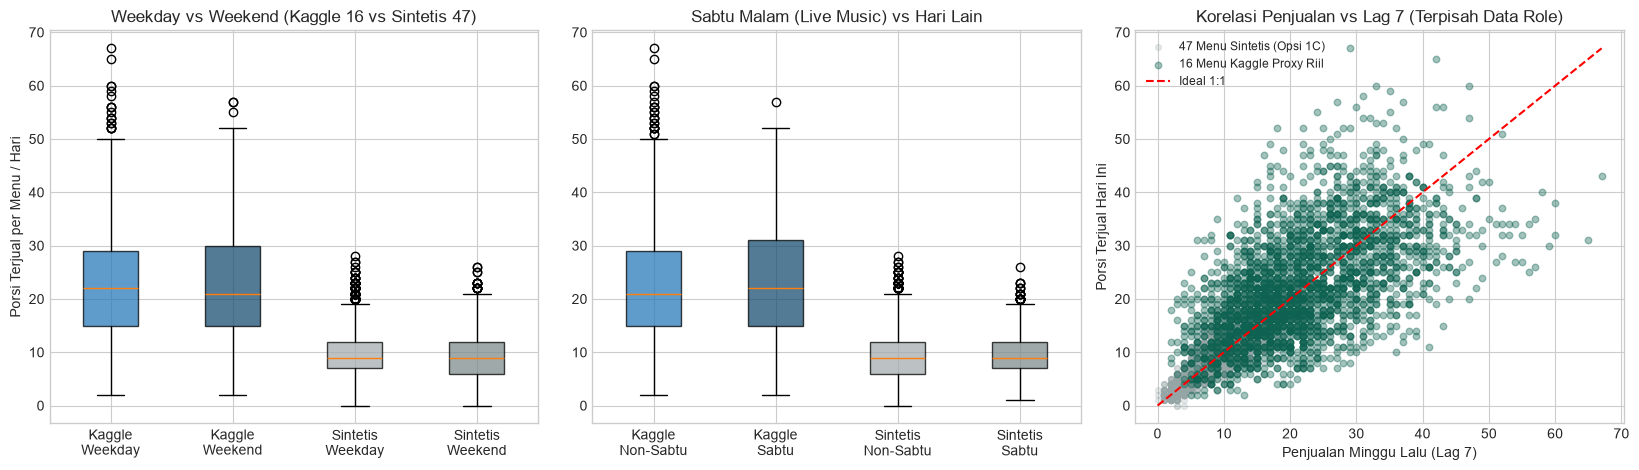

In [10]:
kaggle_clean = clean_df[clean_df['data_role'] == 'external_proxy_not_real_hiroo_sales']
synth_clean = clean_df[clean_df['data_role'] == 'synthetic_dummy_hiroo_catalog']

fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8))

# Plot 1: Weekday vs Weekend terpisah per data_role
bp1 = axes[0].boxplot(
    [
        kaggle_clean[kaggle_clean['is_weekend'] == 0]['units_sold'],
        kaggle_clean[kaggle_clean['is_weekend'] == 1]['units_sold'],
        synth_clean[synth_clean['is_weekend'] == 0]['units_sold'],
        synth_clean[synth_clean['is_weekend'] == 1]['units_sold'],
    ],
    tick_labels=['Kaggle\nWeekday', 'Kaggle\nWeekend', 'Sintetis\nWeekday', 'Sintetis\nWeekend'],
    patch_artist=True
)
for patch, c in zip(bp1['boxes'], ['#2b7bba', '#1b4f72', '#a6acaf', '#7f8c8d']):
    patch.set_facecolor(c)
    patch.set_alpha(0.75)
axes[0].set_title('Weekday vs Weekend (Kaggle 16 vs Sintetis 47)')
axes[0].set_ylabel('Porsi Terjual per Menu / Hari')

# Plot 2: Live Music Night (Sabtu) terpisah per data_role
bp2 = axes[1].boxplot(
    [
        kaggle_clean[kaggle_clean['is_live_music_night'] == 0]['units_sold'],
        kaggle_clean[kaggle_clean['is_live_music_night'] == 1]['units_sold'],
        synth_clean[synth_clean['is_live_music_night'] == 0]['units_sold'],
        synth_clean[synth_clean['is_live_music_night'] == 1]['units_sold'],
    ],
    tick_labels=['Kaggle\nNon-Sabtu', 'Kaggle\nSabtu', 'Sintetis\nNon-Sabtu', 'Sintetis\nSabtu'],
    patch_artist=True
)
for patch, c in zip(bp2['boxes'], ['#2b7bba', '#1b4f72', '#a6acaf', '#7f8c8d']):
    patch.set_facecolor(c)
    patch.set_alpha(0.75)
axes[1].set_title('Sabtu Malam (Live Music) vs Hari Lain')

# Plot 3: Korelasi Lag 7 vs Units Sold dipisah warna data_role
axes[2].scatter(synth_clean['lag_7'], synth_clean['units_sold'], alpha=0.22, color='#95a5a6', label='47 Menu Sintetis (Opsi 1C)', s=18)
axes[2].scatter(kaggle_clean['lag_7'], kaggle_clean['units_sold'], alpha=0.38, color='#0e6251', label='16 Menu Kaggle Proxy Riil', s=22)
max_val = clean_df['units_sold'].max()
axes[2].plot([0, max_val], [0, max_val], 'r--', linewidth=1.5, label='Ideal 1:1')
axes[2].set_title('Korelasi Penjualan vs Lag 7 (Terpisah Data Role)')
axes[2].set_xlabel('Penjualan Minggu Lalu (Lag 7)')
axes[2].set_ylabel('Porsi Terjual Hari Ini')
axes[2].legend(loc='upper left', fontsize=8.5)

plt.tight_layout()
plt.savefig(OUTPUTS_DIR / 'eda_sales_patterns.png', dpi=300)
plt.show()

## 8. Pembagian Data Kronologis Berbasis Waktu (`Chronological 80/20 Split`)
Membagi 167 hari bersih secara kronologis tegas (`80%` awal untuk `Train Set`, `20%` akhir untuk `Test Set`) serta menampilkan rincian baris terpisah antara 16 menu Kaggle riil dan 47 menu sintetis.

In [11]:
unique_dates = np.sort(clean_df['transaction_date'].unique())
split_idx = int(len(unique_dates) * 0.8)
split_date = unique_dates[split_idx]

train_df = clean_df[clean_df['transaction_date'] < split_date].copy()
test_df = clean_df[clean_df['transaction_date'] >= split_date].copy()

assert train_df['transaction_date'].max() < test_df['transaction_date'].min(), "Terjadi tumpang tindih tanggal train/test!"

split_summary = pd.DataFrame([
    {
        'Dataset': 'Train Set (80% Kronologis)',
        'Tanggal Mulai': pd.to_datetime(train_df['transaction_date'].min()).date(),
        'Tanggal Selesai': pd.to_datetime(train_df['transaction_date'].max()).date(),
        'Jumlah Hari': int(train_df['transaction_date'].nunique()),
        'Total Baris (63 Menu)': int(len(train_df)),
        'Baris Kaggle (16 Menu)': int((train_df['data_role'] == 'external_proxy_not_real_hiroo_sales').sum()),
        'Baris Sintetis (47 Menu)': int((train_df['data_role'] == 'synthetic_dummy_hiroo_catalog').sum())
    },
    {
        'Dataset': 'Test Set (20% Kronologis)',
        'Tanggal Mulai': pd.to_datetime(test_df['transaction_date'].min()).date(),
        'Tanggal Selesai': pd.to_datetime(test_df['transaction_date'].max()).date(),
        'Jumlah Hari': int(test_df['transaction_date'].nunique()),
        'Total Baris (63 Menu)': int(len(test_df)),
        'Baris Kaggle (16 Menu)': int((test_df['data_role'] == 'external_proxy_not_real_hiroo_sales').sum()),
        'Baris Sintetis (47 Menu)': int((test_df['data_role'] == 'synthetic_dummy_hiroo_catalog').sum())
    }
])
display(split_summary)
print(f"Tanggal Pemisah Kronologis (Cutoff Date): {pd.to_datetime(split_date).date()}")

,Dataset,Tanggal Mulai,Tanggal Selesai,Jumlah Hari,Total Baris (63 Menu),Baris Kaggle (16 Menu),Baris Sintetis (47 Menu)
0,Train Set (80% Kronologis),2023-01-15,2023-05-27,133,8379,2128,6251
1,Test Set (20% Kronologis),2023-05-28,2023-06-30,34,2142,544,1598


Tanggal Pemisah Kronologis (Cutoff Date): 2023-05-28


## 9. Pembangunan Pipeline Preprocessor `ColumnTransformer`
Mengisolasi transformasi fitur menggunakan `ColumnTransformer`: `StandardScaler` untuk 8 fitur numerik (`day_of_week`, `is_live_music_night`, `is_weekend`, `lag_1`, `lag_7`, `lag_14`, `rolling_mean_7`, `rolling_mean_14`) dan `OneHotEncoder(handle_unknown='ignore')` untuk identitas menu (`hiroo_menu`).

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = ['day_of_week', 'is_live_music_night', 'is_weekend', 'lag_1', 'lag_7', 'lag_14', 'rolling_mean_7', 'rolling_mean_14']
categorical_features = ['hiroo_menu']
feature_cols = categorical_features + numeric_features

X_train, y_train = train_df[feature_cols], train_df['units_sold']
X_test, y_test = test_df[feature_cols], test_df['units_sold']

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numeric_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
])

print("Pipeline ColumnTransformer Berhasil Dikonfigurasi:")
print(f"  - Fitur Numerik ({len(numeric_features)})     : {numeric_features}")
print(f"  - Fitur Kategorikal ({len(categorical_features)}) : {categorical_features}")

Pipeline ColumnTransformer Berhasil Dikonfigurasi:
  - Fitur Numerik (8)     : ['day_of_week', 'is_live_music_night', 'is_weekend', 'lag_1', 'lag_7', 'lag_14', 'rolling_mean_7', 'rolling_mean_14']
  - Fitur Kategorikal (1) : ['hiroo_menu']


## 10. Pelatihan & Benchmark Multi-Model dengan Evaluasi Terpisah (*Disaggregated Benchmark*)
Melatih 4 model (`Baseline (7-day MA)`, `Ridge Regression`, `Random Forest (Tuned)`, `Gradient Boosting Regressor`) dan melaporkan `MAE (Porsi)`, `RMSE (Porsi)`, `WAPE (%)`, `R2 Score`, serta `Skill vs Baseline (%)` secara terpisah untuk:
1. **Combined (63 Menu)**
2. **Subset 16 Menu Kaggle Proxy Riil (`external_proxy_not_real_hiroo_sales`)** — ukuran performa objektif bebas *self-fulfilling prophecy*
3. **Subset 47 Menu Sintetis (`synthetic_dummy_hiroo_catalog`)**

In [13]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

def eval_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = root_mean_squared_error(y_true, y_pred)
    wape = (np.sum(np.abs(y_true - y_pred)) / np.sum(np.abs(y_true))) * 100.0
    r2 = r2_score(y_true, y_pred)
    return mae, rmse, wape, r2

# Latih Pipeline ML (tanpa emoji di nama model agar bebas warning glyph matplotlib)
trained_pipelines = {}

ridge_pipe = Pipeline([('preprocessor', preprocessor), ('regressor', Ridge(alpha=10.0, random_state=42))])
ridge_pipe.fit(X_train, y_train)
trained_pipelines['Ridge Regression'] = ridge_pipe

rf_pipe = Pipeline([('preprocessor', preprocessor), ('regressor', RandomForestRegressor(n_estimators=100, max_depth=12, min_samples_split=4, min_samples_leaf=2, random_state=42, n_jobs=-1))])
rf_pipe.fit(X_train, y_train)
trained_pipelines['Random Forest (Tuned)'] = rf_pipe

gb_pipe = Pipeline([('preprocessor', preprocessor), ('regressor', GradientBoostingRegressor(n_estimators=100, max_depth=5, learning_rate=0.08, random_state=42))])
gb_pipe.fit(X_train, y_train)
trained_pipelines['Gradient Boosting Regressor'] = gb_pipe

# Prediksi pada seluruh Test Set
test_preds = {
    'Baseline (7-day MA)': np.clip(test_df['rolling_mean_7'].values, 0, None),
    'Ridge Regression': np.clip(ridge_pipe.predict(X_test), 0, None),
    'Random Forest (Tuned)': np.clip(rf_pipe.predict(X_test), 0, None),
    'Gradient Boosting Regressor': np.clip(gb_pipe.predict(X_test), 0, None),
}

def build_benchmark_table(mask, subset_label):
    y_sub = y_test.values[mask]
    base_mae = mean_absolute_error(y_sub, test_preds['Baseline (7-day MA)'][mask])
    rows = []
    for m_name, preds_all in test_preds.items():
        p_sub = preds_all[mask]
        mae, rmse, wape, r2 = eval_metrics(y_sub, p_sub)
        skill_pct = ((base_mae - mae) / base_mae) * 100.0
        rows.append({
            'Model': m_name,
            'Subset': subset_label,
            'MAE (Porsi)': round(mae, 4),
            'RMSE (Porsi)': round(rmse, 4),
            'WAPE (%)': round(wape, 2),
            'R2 Score': round(r2, 4),
            'Skill vs Baseline (%)': round(skill_pct, 2)
        })
    return pd.DataFrame(rows)

mask_all = np.ones(len(test_df), dtype=bool)
mask_kaggle = (test_df['data_role'] == 'external_proxy_not_real_hiroo_sales').values
mask_synth = (test_df['data_role'] == 'synthetic_dummy_hiroo_catalog').values

benchmark_df = build_benchmark_table(mask_all, 'Combined (63 Menus)')
benchmark_kaggle_df = build_benchmark_table(mask_kaggle, 'Kaggle Real Proxy (16 Menus)')
benchmark_synth_df = build_benchmark_table(mask_synth, 'Synthetic Dummy (47 Menus)')

print("=== 1. BENCHMARK GABUNGAN (63 Menu: 16 Kaggle + 47 Sintetis) ===")
display(benchmark_df)

print("=== 2. BENCHMARK JUJUR SUBSET 16 MENU KAGGLE RIIL (external_proxy_not_real_hiroo_sales) ===")
display(benchmark_kaggle_df)

print("=== 3. BENCHMARK SUBSET 47 MENU SINTETIS (synthetic_dummy_hiroo_catalog — Opsi 1C) ===")
display(benchmark_synth_df)

=== 1. BENCHMARK GABUNGAN (63 Menu: 16 Kaggle + 47 Sintetis) ===


,Model,Subset,MAE (Porsi),RMSE (Porsi),WAPE (%),R2 Score,Skill vs Baseline (%)
0,Baseline (7-day MA),Combined (63 Menus),2.9543,4.7911,16.58,0.7743,0.00
1,Ridge Regression,Combined (63 Menus),2.8986,4.6626,16.26,0.7862,1.89
2,Random Forest (Tuned),Combined (63 Menus),2.9557,4.8118,16.59,0.7723,-0.05
3,Gradient Boosting Regressor,Combined (63 Menus),3.0587,5.0255,17.16,0.7517,-3.53


=== 2. BENCHMARK JUJUR SUBSET 16 MENU KAGGLE RIIL (external_proxy_not_real_hiroo_sales) ===


,Model,Subset,MAE (Porsi),RMSE (Porsi),WAPE (%),R2 Score,Skill vs Baseline (%)
0,Baseline (7-day MA),Kaggle Real Proxy (16 Menus),6.8395,8.7881,21.99,0.2444,0.00
1,Ridge Regression,Kaggle Real Proxy (16 Menus),6.6884,8.5337,21.50,0.2875,2.21
2,Random Forest (Tuned),Kaggle Real Proxy (16 Menus),6.7996,8.7964,21.86,0.2429,0.58
3,Gradient Boosting Regressor,Kaggle Real Proxy (16 Menus),7.1883,9.2617,23.11,0.1607,-5.10


=== 3. BENCHMARK SUBSET 47 MENU SINTETIS (synthetic_dummy_hiroo_catalog — Opsi 1C) ===


,Model,Subset,MAE (Porsi),RMSE (Porsi),WAPE (%),R2 Score,Skill vs Baseline (%)
0,Baseline (7-day MA),Synthetic Dummy (47 Menus),1.6317,2.1160,12.27,0.7871,0.00
1,Ridge Regression,Synthetic Dummy (47 Menus),1.6084,2.0856,12.09,0.7932,1.43
2,Random Forest (Tuned),Synthetic Dummy (47 Menus),1.6471,2.1667,12.38,0.7768,-0.94
3,Gradient Boosting Regressor,Synthetic Dummy (47 Menus),1.6529,2.1569,12.43,0.7788,-1.30


## 11. Rekapitulasi, Visualisasi Komparasi, & Seleksi Dinamis Model Pemenang (`Opsi 3B: MAE (Porsi)`)
Memilih model pemenang secara programatik berdasarkan `PRIMARY_METRIC = 'MAE (Porsi)'` terendah (tanpa angka/model *hardcoded*) serta memverifikasi bahwa pemenang mengungguli `Baseline (7-day MA)` baik pada gabungan 63 menu maupun subset 16 menu Kaggle riil.

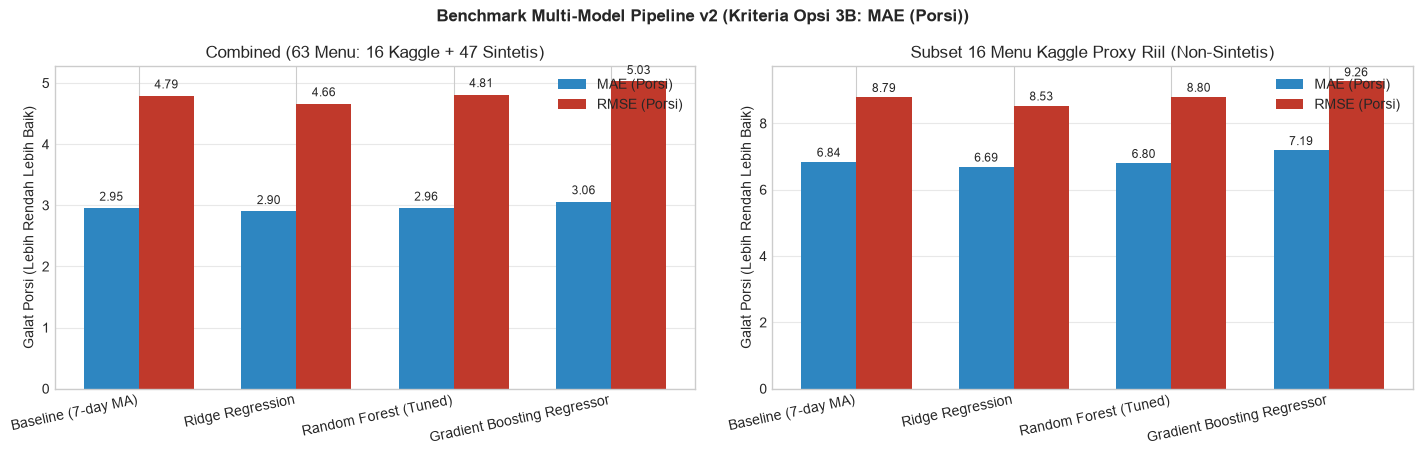

PASS — Pemenang Dinamis (Opsi 3B, MAE (Porsi)): Ridge Regression
  - Combined (63 Menu)  : MAE=2.8986, RMSE=4.6626, WAPE=16.26%, R2=0.7862, Skill=1.89%
  - Kaggle 16 Menu Riil : MAE=6.6884, RMSE=8.5337, WAPE=21.5%, R2=0.2875, Skill=2.21% (Baseline MAE=6.8395)


In [14]:
# Seleksi Dinamis Sesuai Opsi 3B (MAE Porsi Terendah)
PRIMARY_METRIC = 'MAE (Porsi)'
candidates_combined = benchmark_df[benchmark_df['Model'] != 'Baseline (7-day MA)']
best_row = candidates_combined.sort_values(PRIMARY_METRIC, ascending=True).iloc[0]
best_model_name = best_row['Model']
best_pipe = trained_pipelines[best_model_name]

# Cek performa pemenang & ranking pada Subset 16 Menu Kaggle Riil
kaggle_base_mae = float(benchmark_kaggle_df[benchmark_kaggle_df['Model'] == 'Baseline (7-day MA)']['MAE (Porsi)'].iloc[0])
best_kaggle_row = benchmark_kaggle_df[benchmark_kaggle_df['Model'] == best_model_name].iloc[0]
kaggle_best_overall = benchmark_kaggle_df[benchmark_kaggle_df['Model'] != 'Baseline (7-day MA)'].sort_values(PRIMARY_METRIC, ascending=True).iloc[0]

assert float(best_kaggle_row['MAE (Porsi)']) < kaggle_base_mae, (
    f"Pemenang {best_model_name} (Kaggle MAE={best_kaggle_row['MAE (Porsi)']}) gagal mengalahkan Baseline ({kaggle_base_mae})!"
)

# Visualisasi Komparasi MAE & RMSE (Gabungan 63 Menu vs 16 Menu Kaggle Riil)
fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.6))
x_idx = np.arange(len(benchmark_df))
w = 0.35

for ax, df_plot, title in [
    (axes[0], benchmark_df, 'Combined (63 Menu: 16 Kaggle + 47 Sintetis)'),
    (axes[1], benchmark_kaggle_df, 'Subset 16 Menu Kaggle Proxy Riil (Non-Sintetis)')
]:
    b1 = ax.bar(x_idx - w/2, df_plot['MAE (Porsi)'], width=w, label='MAE (Porsi)', color='#2e86c1')
    b2 = ax.bar(x_idx + w/2, df_plot['RMSE (Porsi)'], width=w, label='RMSE (Porsi)', color='#c0392b')
    for bar in list(b1) + list(b2):
        yv = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, yv + 0.08, f"{yv:.2f}", ha='center', va='bottom', fontsize=8.5)
    ax.set_xticks(x_idx)
    ax.set_xticklabels(df_plot['Model'], rotation=12, ha='right')
    ax.set_ylabel('Galat Porsi (Lebih Rendah Lebih Baik)')
    ax.set_title(title)
    ax.legend(loc='upper right')
    ax.grid(axis='y', alpha=0.45)

plt.suptitle(f"Benchmark Multi-Model Pipeline v2 (Kriteria Opsi 3B: {PRIMARY_METRIC})", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUTS_DIR / 'model_benchmark_comparison.png', dpi=300)
plt.show()

print(f"PASS — Pemenang Dinamis (Opsi 3B, {PRIMARY_METRIC}): {best_model_name}")
print(f"  - Combined (63 Menu)  : MAE={best_row['MAE (Porsi)']}, RMSE={best_row['RMSE (Porsi)']}, WAPE={best_row['WAPE (%)']}%, R2={best_row['R2 Score']}, Skill={best_row['Skill vs Baseline (%)']}%")
print(f"  - Kaggle 16 Menu Riil : MAE={best_kaggle_row['MAE (Porsi)']}, RMSE={best_kaggle_row['RMSE (Porsi)']}, WAPE={best_kaggle_row['WAPE (%)']}%, R2={best_kaggle_row['R2 Score']}, Skill={best_kaggle_row['Skill vs Baseline (%)']}% (Baseline MAE={kaggle_base_mae})")
if kaggle_best_overall['Model'] != best_model_name:
    print(f"  - Catatan Audit       : Pada subset 16 menu Kaggle saja, MAE terendah dicapai oleh '{kaggle_best_overall['Model']}' ({kaggle_best_overall['MAE (Porsi)']}).")

## 12. Validasi Silang Makro Subset In-Scope (16 Menu Kaggle Riil) & Rasio Cakupan Toko
Menghitung penjumlahan prediksi `best_pipe` pada Test Set **khusus untuk subset 16 menu Kaggle riil (`external_proxy_not_real_hiroo_sales`)** lalu memvalidasinya terhadap subtotal harian aktual ke-16 SKU tersebut (`MAPE < 15%`), sekaligus melaporkan secara transparan rasio cakupannya terhadap total kedai `daily_reference.csv` (`29,90%`) agar data sintetis Opsi 1C tidak mendistorsi rekonsiliasi.

,Jumlah Hari Validasi,Model Pembanding,Rata-rata Aktual 16 Menu/Hari,Rata-rata Prediksi 16 Menu/Hari,Subset 16-Menu MAE,Subset 16-Menu RMSE,Subset 16-Menu MAPE,Cakupan 16 Menu vs Total Toko (181h),Cakupan 16 Menu vs Total Toko (Test)
0,34,Ridge Regression,497.6,498.8,38.52,45.81,7.93%,29.90%,29.94%


PASS: Validasi makro subset 16 menu Kaggle konsisten dengan MAPE = 7.93% (Target < 15.0%).
Transparansi Cakupan: 16 menu Strict 1-to-1 mewakili 29.90% volume total toko di daily_reference.csv.


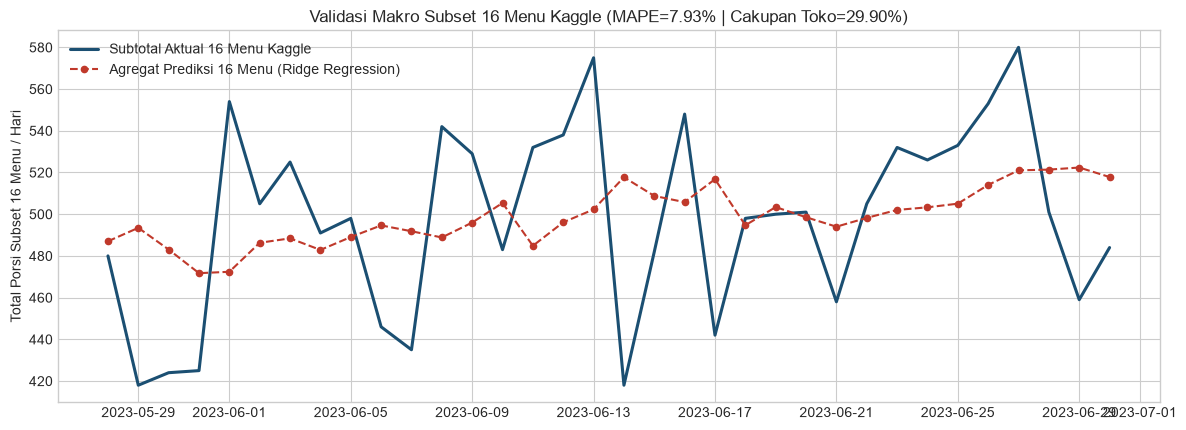

In [15]:
# Filter khusus subset 16 menu Kaggle riil pada Test Set
val_kaggle_df = test_df[test_df['data_role'] == 'external_proxy_not_real_hiroo_sales'][['transaction_date', 'hiroo_menu', 'units_sold']].copy()
val_kaggle_df['predicted_units'] = test_preds[best_model_name][mask_kaggle]

agg_16_pred = val_kaggle_df.groupby('transaction_date', as_index=False).agg(
    actual_16_subtotal=('units_sold', 'sum'),
    predicted_16_subtotal=('predicted_units', 'sum')
)
daily_total_ref = df_daily[['transaction_date', 'units_sold']].rename(columns={'units_sold': 'actual_store_total_daily'})
merged_store = pd.merge(agg_16_pred, daily_total_ref, on='transaction_date', how='inner')

# Metrik Validasi Makro pada Subset 16 Menu Riil
daily_mae = mean_absolute_error(merged_store['actual_16_subtotal'], merged_store['predicted_16_subtotal'])
daily_rmse = root_mean_squared_error(merged_store['actual_16_subtotal'], merged_store['predicted_16_subtotal'])
daily_mape = float(np.mean(np.abs((merged_store['actual_16_subtotal'] - merged_store['predicted_16_subtotal']) / merged_store['actual_16_subtotal'])) * 100.0)

# Rasio Cakupan terhadap Total Kedai (daily_reference.csv)
store_coverage_test_pct = float((merged_store['actual_16_subtotal'].sum() / merged_store['actual_store_total_daily'].sum()) * 100.0)
store_coverage_full_pct = float((df_hiroo_daily[df_hiroo_daily['data_role'] == 'external_proxy_not_real_hiroo_sales']['units_sold'].sum() / df_daily['units_sold'].sum()) * 100.0)

validation_summary = pd.DataFrame([{
    'Jumlah Hari Validasi': int(len(merged_store)),
    'Model Pembanding': best_model_name,
    'Rata-rata Aktual 16 Menu/Hari': round(float(merged_store['actual_16_subtotal'].mean()), 1),
    'Rata-rata Prediksi 16 Menu/Hari': round(float(merged_store['predicted_16_subtotal'].mean()), 1),
    'Subset 16-Menu MAE': round(float(daily_mae), 2),
    'Subset 16-Menu RMSE': round(float(daily_rmse), 2),
    'Subset 16-Menu MAPE': f"{daily_mape:.2f}%",
    'Cakupan 16 Menu vs Total Toko (181h)': f"{store_coverage_full_pct:.2f}%",
    'Cakupan 16 Menu vs Total Toko (Test)': f"{store_coverage_test_pct:.2f}%"
}])
display(validation_summary)

assert daily_mape < 15.0, f"MAPE subset 16 menu {daily_mape:.2f}% melebihi ambang batas 15%!"
print(f"PASS: Validasi makro subset 16 menu Kaggle konsisten dengan MAPE = {daily_mape:.2f}% (Target < 15.0%).")
print(f"Transparansi Cakupan: 16 menu Strict 1-to-1 mewakili {store_coverage_full_pct:.2f}% volume total toko di daily_reference.csv.")

# Plot Actual vs Predicted Subset 16 Menu + Konteks Total Toko
fig, ax = plt.subplots(figsize=(12, 4.4))
ax.plot(merged_store['transaction_date'], merged_store['actual_16_subtotal'], label='Subtotal Aktual 16 Menu Kaggle', color='#1b4f72', linewidth=2.2)
ax.plot(merged_store['transaction_date'], merged_store['predicted_16_subtotal'], label=f'Agregat Prediksi 16 Menu ({best_model_name})', color='#c0392b', linestyle='--', marker='o', markersize=4.5)
ax.set_title(f'Validasi Makro Subset 16 Menu Kaggle (MAPE={daily_mape:.2f}% | Cakupan Toko={store_coverage_full_pct:.2f}%)')
ax.set_ylabel('Total Porsi Subset 16 Menu / Hari')
ax.legend(loc='upper left')
plt.tight_layout()
plt.savefig(OUTPUTS_DIR / 'store_level_validation.png', dpi=300)
plt.show()

## 13. Pelatihan Penuh pada 100% Data & Ekspor Artefak `sales_forecaster.joblib`
Melakukan `clone(best_pipe)` dan melatih ulang model pemenang pada 100% data bersih (`10.521` baris = `63 menu × 167 hari`), lalu mengekspor `outputs/sales_forecaster.joblib` lengkap dengan `last_30_days_history` (seluruh 63 menu), `catalog_df`, **Dual-Key Adapter (Opsi 4A)**, kontrak POS FS, serta `metadata` sinkron 100% terhadap `benchmark_df`.

In [16]:
from sklearn.base import clone

final_pipeline = clone(best_pipe)
final_pipeline.fit(clean_df[feature_cols], clean_df['units_sold'])

max_hist_date = clean_df['transaction_date'].max()
hist_start = max_hist_date - pd.Timedelta(days=30)
last_30_days_df = clean_df[clean_df['transaction_date'] >= hist_start][
    ['transaction_date', 'menu_id', 'hiroo_menu', 'data_role', 'units_sold']
].copy()

assert last_30_days_df['hiroo_menu'].nunique() == 63

# Sinkronisasi metadata 100% dengan baris pemenang benchmark_df & benchmark_kaggle_df
artifact_metadata = {
    'pipeline_version': 'v2',
    'serving_policy': 'Opsi 1C (full 63-menu ML) + Opsi 4A (Dual-Key Adapter, no cold-start fallback)',
    'primary_metric': PRIMARY_METRIC,
    'model_name': best_model_name,
    'data_source': 'hiroo_ae_playground',
    'combined_63_metrics': {
        'mae_porsi': float(best_row['MAE (Porsi)']),
        'rmse_porsi': float(best_row['RMSE (Porsi)']),
        'wape_pct': float(best_row['WAPE (%)']),
        'r2_score': float(best_row['R2 Score']),
        'skill_vs_baseline_pct': float(best_row['Skill vs Baseline (%)'])
    },
    'kaggle_16_real_metrics': {
        'mae_porsi': float(best_kaggle_row['MAE (Porsi)']),
        'rmse_porsi': float(best_kaggle_row['RMSE (Porsi)']),
        'wape_pct': float(best_kaggle_row['WAPE (%)']),
        'r2_score': float(best_kaggle_row['R2 Score']),
        'skill_vs_baseline_pct': float(best_kaggle_row['Skill vs Baseline (%)'])
    },
    'macro_16_subset_mape': f"{daily_mape:.2f}%",
    'kaggle_16_store_coverage_pct': round(store_coverage_full_pct, 2),
    'total_menus': int(len(catalog_df)),
    'kaggle_real_proxy_menus': int((ae_catalog_lineage_audit_df['data_role'] == 'external_proxy_not_real_hiroo_sales').sum()),
    'synthetic_dummy_menus': int((ae_catalog_lineage_audit_df['data_role'] == 'synthetic_dummy_hiroo_catalog').sum())
}

artifact = {
    'pipeline': final_pipeline,
    'feature_cols': feature_cols,
    'numeric_features': numeric_features,
    'categorical_features': categorical_features,
    'last_30_days_history': last_30_days_df,
    'menu_list': sorted(catalog_df['menu_name'].tolist()),
    'catalog_df': catalog_df,
    'dual_key_adapter': dual_key_adapter,
    'fs_seed_alignment_df': fs_seed_alignment_df,
    'pos_fs_contract': pos_fs_contract,
    'metadata': artifact_metadata
}

joblib_path = OUTPUTS_DIR / 'sales_forecaster.joblib'
joblib.dump(artifact, joblib_path)
print(f"PASS: Artefak Pipeline v2 tersimpan ke: {joblib_path}")
print(f"Ukuran Berkas: {joblib_path.stat().st_size / (1024*1024):.4f} MB")
print("Metadata tersimpan:", json.dumps(artifact_metadata, indent=2))

PASS: Artefak Pipeline v2 tersimpan ke: C:\Users\rilob\BELAJAR PROGRAMMING\Asah Dicoding 2026\tongkrongan-hiroo\hiroo_ae_playground\outputs\sales_forecaster.joblib
Ukuran Berkas: 0.0895 MB
Metadata tersimpan: {
  "pipeline_version": "v2",
  "serving_policy": "Opsi 1C (full 63-menu ML) + Opsi 4A (Dual-Key Adapter, no cold-start fallback)",
  "primary_metric": "MAE (Porsi)",
  "model_name": "Ridge Regression",
  "data_source": "hiroo_ae_playground",
  "combined_63_metrics": {
    "mae_porsi": 2.8986,
    "rmse_porsi": 4.6626,
    "wape_pct": 16.26,
    "r2_score": 0.7862,
    "skill_vs_baseline_pct": 1.89
  },
  "kaggle_16_real_metrics": {
    "mae_porsi": 6.6884,
    "rmse_porsi": 8.5337,
    "wape_pct": 21.5,
    "r2_score": 0.2875,
    "skill_vs_baseline_pct": 2.21
  },
  "macro_16_subset_mape": "7.93%",
  "kaggle_16_store_coverage_pct": 29.9,
  "total_menus": 63,
  "kaggle_real_proxy_menus": 16,
  "synthetic_dummy_menus": 47
}


## 14. Fungsi Inferensi Autoregressive 7 Hari dengan *Dual-Key Adapter* (`Opsi 4A`)
Memperbarui `simulate_forecast(artifact_obj, menu_key, n_days=7)` agar menerima seluruh format kunci menu (`MNU-001`–`MNU-063`, kode DB FS `KOP-01`..`MAK-02`, integer `menus.id` `1`..`13`, serta nama baku maupun alias lama seperti `'Coffee Milk Hiroo'`, `'Choco malt'`, dan `'Dimsum'`), menjalankan prediksi ML penuh 63 menu tanpa *cold-start fallback* (sesuai Opsi 1C + 4A), serta menyertakan metadata `data_role`, `is_bundle`, `fs_seed_alignment`, dan `lineage_note`.

In [17]:
def resolve_menu_key(artifact_obj, menu_key):
    adapter = artifact_obj['dual_key_adapter']
    if isinstance(menu_key, (int, np.integer)):
        lookup = str(int(menu_key))
    else:
        raw = str(menu_key).strip()
        if raw.upper() in adapter:
            lookup = raw.upper()
        elif raw.lower() in adapter:
            lookup = raw.lower()
        else:
            lookup = raw
    assert lookup in adapter, f"Kunci menu '{menu_key}' tidak ditemukan pada Dual-Key Adapter!"
    return adapter[lookup]

def simulate_forecast(artifact_obj, menu_key, n_days=7):
    resolved = resolve_menu_key(artifact_obj, menu_key)
    menu_name = resolved['menu_name']
    menu_id = resolved['menu_id']

    pipe = artifact_obj['pipeline']
    history = artifact_obj['last_30_days_history']

    menu_hist = history[history['hiroo_menu'] == menu_name].sort_values('transaction_date')
    assert len(menu_hist) >= 14, f"Riwayat menu {menu_name} ({menu_id}) kurang dari 14 hari."

    data_role = str(menu_hist['data_role'].iloc[0])
    lineage_note = (
        "Proxy Kaggle 1-to-1 (bukan penjualan riil Hiroo)."
        if data_role == 'external_proxy_not_real_hiroo_sales'
        else "Data dummy sintetis katalog (Opsi 1C, menunggu >=14 hari POS nyata Hiroo)."
    )

    hist_vals = list(menu_hist['units_sold'].values)
    curr_dt = menu_hist['transaction_date'].max()

    results = []
    for _ in range(n_days):
        curr_dt += pd.Timedelta(days=1)
        dow = curr_dt.dayofweek
        live_music = 1 if dow == 5 else 0
        wknd = 1 if dow in [5, 6] else 0

        row_features = pd.DataFrame([{
            'hiroo_menu': menu_name,
            'day_of_week': dow,
            'is_live_music_night': live_music,
            'is_weekend': wknd,
            'lag_1': hist_vals[-1],
            'lag_7': hist_vals[-7],
            'lag_14': hist_vals[-14],
            'rolling_mean_7': float(np.mean(hist_vals[-7:])),
            'rolling_mean_14': float(np.mean(hist_vals[-14:]))
        }])

        pred_val = float(np.clip(pipe.predict(row_features)[0], 0, None))
        hist_vals.append(pred_val)

        results.append({
            'menu_id': menu_id,
            'menu_name': menu_name,
            'Tanggal': curr_dt.strftime('%Y-%m-%d'),
            'Hari': curr_dt.strftime('%A'),
            'Sabtu Malam (Live Music)?': 'Ya' if live_music else 'Tidak',
            'Estimasi Porsi Terjual': round(pred_val, 1),
            'data_role': data_role,
            'is_bundle': bool(resolved.get('is_bundle', False)),
            'fs_seed_alignment': resolved.get('fs_seed_alignment', 'canonical_63_menu_catalog'),
            'lineage_note': lineage_note
        })
    return pd.DataFrame(results)

# Uji Multi-Key: MNU-026 (Kaggle), KOP-01 (FS Code), 1 (FS ID), MNU-059 (Republik Hiroo Bundle), & Dimsum (Alias)
print("1) Uji MNU-026 (Ice Coffee Milk Hiroo - Kaggle Proxy):")
display(simulate_forecast(artifact, 'MNU-026', n_days=7))

print("2) Uji KOP-01 (FS Seed Code) vs Legacy 'Coffee Milk Hiroo' vs menus.id=1:")
f_kop01 = simulate_forecast(artifact, 'KOP-01', n_days=3)
f_id1 = simulate_forecast(artifact, 1, n_days=3)
f_legacy = simulate_forecast(artifact, 'Coffee Milk Hiroo', n_days=3)
assert f_kop01['menu_id'].iloc[0] == f_id1['menu_id'].iloc[0] == f_legacy['menu_id'].iloc[0] == 'MNU-026'
display(f_kop01)

print("3) Uji MNU-059 (Paket Republik Hiroo - Synthetic Dummy Opsi 1C) & Alias 'Dimsum' -> MNU-063:")
display(simulate_forecast(artifact, 'MNU-059', n_days=3))
f_dimsum = simulate_forecast(artifact, 'Dimsum', n_days=3)
assert f_dimsum['menu_id'].iloc[0] == 'MNU-063'
display(f_dimsum)

# Stress test menyeluruh: seluruh 63 MNU-xxx, seluruh 13 DB FS codes, seluruh 13 DB FS ids
for mid in catalog_df['menu_id']:
    res_df = simulate_forecast(artifact, mid, n_days=7)
    assert len(res_df) == 7 and res_df['Estimasi Porsi Terjual'].notnull().all()
for fcode in fs_seed_alignment_df['fs_code']:
    res_df = simulate_forecast(artifact, fcode, n_days=7)
    assert len(res_df) == 7
for fid in fs_seed_alignment_df['fs_menu_id']:
    res_df = simulate_forecast(artifact, int(fid), n_days=7)
    assert len(res_df) == 7

print("PASS: Seluruh 63 MNU-001..063, 13 kode FS (KOP-01..MAK-02), 13 menus.id (1..13), & alias nama berhasil diramal via ML!")

1) Uji MNU-026 (Ice Coffee Milk Hiroo - Kaggle Proxy):


,menu_id,menu_name,Tanggal,Hari,Sabtu Malam (Live Music)?,Estimasi Porsi Terjual,data_role,is_bundle,fs_seed_alignment,lineage_note
0,MNU-026,Ice Coffee Milk Hiroo,2023-07-01,Saturday,Ya,35.9,external_proxy_not_real_hiroo_sales,False,canonical_63_menu_catalog,Proxy Kaggle 1-to-1 (bukan penjualan riil Hiroo).
1,MNU-026,Ice Coffee Milk Hiroo,2023-07-02,Sunday,Tidak,37.0,external_proxy_not_real_hiroo_sales,False,canonical_63_menu_catalog,Proxy Kaggle 1-to-1 (bukan penjualan riil Hiroo).
2,MNU-026,Ice Coffee Milk Hiroo,2023-07-03,Monday,Tidak,37.2,external_proxy_not_real_hiroo_sales,False,canonical_63_menu_catalog,Proxy Kaggle 1-to-1 (bukan penjualan riil Hiroo).
3,MNU-026,Ice Coffee Milk Hiroo,2023-07-04,Tuesday,Tidak,37.2,external_proxy_not_real_hiroo_sales,False,canonical_63_menu_catalog,Proxy Kaggle 1-to-1 (bukan penjualan riil Hiroo).
4,MNU-026,Ice Coffee Milk Hiroo,2023-07-05,Wednesday,Tidak,37.2,external_proxy_not_real_hiroo_sales,False,canonical_63_menu_catalog,Proxy Kaggle 1-to-1 (bukan penjualan riil Hiroo).
5,MNU-026,Ice Coffee Milk Hiroo,2023-07-06,Thursday,Tidak,37.2,external_proxy_not_real_hiroo_sales,False,canonical_63_menu_catalog,Proxy Kaggle 1-to-1 (bukan penjualan riil Hiroo).
6,MNU-026,Ice Coffee Milk Hiroo,2023-07-07,Friday,Tidak,38.7,external_proxy_not_real_hiroo_sales,False,canonical_63_menu_catalog,Proxy Kaggle 1-to-1 (bukan penjualan riil Hiroo).


2) Uji KOP-01 (FS Seed Code) vs Legacy 'Coffee Milk Hiroo' vs menus.id=1:


,menu_id,menu_name,Tanggal,Hari,Sabtu Malam (Live Music)?,Estimasi Porsi Terjual,data_role,is_bundle,fs_seed_alignment,lineage_note
0,MNU-026,Ice Coffee Milk Hiroo,2023-07-01,Saturday,Ya,35.9,external_proxy_not_real_hiroo_sales,False,direct_semantic_match_price_diff,Proxy Kaggle 1-to-1 (bukan penjualan riil Hiroo).
1,MNU-026,Ice Coffee Milk Hiroo,2023-07-02,Sunday,Tidak,37.0,external_proxy_not_real_hiroo_sales,False,direct_semantic_match_price_diff,Proxy Kaggle 1-to-1 (bukan penjualan riil Hiroo).
2,MNU-026,Ice Coffee Milk Hiroo,2023-07-03,Monday,Tidak,37.2,external_proxy_not_real_hiroo_sales,False,direct_semantic_match_price_diff,Proxy Kaggle 1-to-1 (bukan penjualan riil Hiroo).


3) Uji MNU-059 (Paket Republik Hiroo - Synthetic Dummy Opsi 1C) & Alias 'Dimsum' -> MNU-063:


,menu_id,menu_name,Tanggal,Hari,Sabtu Malam (Live Music)?,Estimasi Porsi Terjual,data_role,is_bundle,fs_seed_alignment,lineage_note
0,MNU-059,Roti Picisan Hiroo + Hazelnut Latte,2023-07-01,Saturday,Ya,4.9,synthetic_dummy_hiroo_catalog,True,canonical_63_menu_catalog,"Data dummy sintetis katalog (Opsi 1C, menunggu >=14 hari POS nyata Hiroo)."
1,MNU-059,Roti Picisan Hiroo + Hazelnut Latte,2023-07-02,Sunday,Tidak,4.6,synthetic_dummy_hiroo_catalog,True,canonical_63_menu_catalog,"Data dummy sintetis katalog (Opsi 1C, menunggu >=14 hari POS nyata Hiroo)."
2,MNU-059,Roti Picisan Hiroo + Hazelnut Latte,2023-07-03,Monday,Tidak,4.8,synthetic_dummy_hiroo_catalog,True,canonical_63_menu_catalog,"Data dummy sintetis katalog (Opsi 1C, menunggu >=14 hari POS nyata Hiroo)."


,menu_id,menu_name,Tanggal,Hari,Sabtu Malam (Live Music)?,Estimasi Porsi Terjual,data_role,is_bundle,fs_seed_alignment,lineage_note
0,MNU-063,Otak-otak / Dimsum,2023-07-01,Saturday,Ya,5.7,synthetic_dummy_hiroo_catalog,True,section_2g_short_name,"Data dummy sintetis katalog (Opsi 1C, menunggu >=14 hari POS nyata Hiroo)."
1,MNU-063,Otak-otak / Dimsum,2023-07-02,Sunday,Tidak,5.2,synthetic_dummy_hiroo_catalog,True,section_2g_short_name,"Data dummy sintetis katalog (Opsi 1C, menunggu >=14 hari POS nyata Hiroo)."
2,MNU-063,Otak-otak / Dimsum,2023-07-03,Monday,Tidak,5.4,synthetic_dummy_hiroo_catalog,True,section_2g_short_name,"Data dummy sintetis katalog (Opsi 1C, menunggu >=14 hari POS nyata Hiroo)."


PASS: Seluruh 63 MNU-001..063, 13 kode FS (KOP-01..MAK-02), 13 menus.id (1..13), & alias nama berhasil diramal via ML!


## 15. Generator Pre-Aggregated Payload untuk Modul Generative AI (Bebas Bias & Dinamis)
Menghitung ranking *hero* & *slow-moving* **eksklusif dari 16 menu Kaggle 1-to-1 (`external_proxy_not_real_hiroo_sales`)** agar 100% bebas bias ukuran ember maupun distorsi data dummy Opsi 1C, menentukan `busiest_day` & `quietest_day` secara dinamis dari `dow_stats` (terpisah dari konteks operasional Live Music Sabtu Hiroo), memperbaiki format tanda `f"{weekend_uplift_pct:+.1f}%"`, serta menjaga kepatuhan `DATA_DICTIONARY.md` tanpa simbol `Rp` pada `sales_value` Kaggle.

In [18]:
# 1. Agregasi Temporal Dinamis dari daily_reference.csv
df_daily['day_name'] = df_daily['transaction_date'].dt.day_name()
df_daily['is_weekend'] = df_daily['transaction_date'].dt.dayofweek.isin([5, 6]).astype(int)

dow_stats_df = df_daily.groupby('day_name').agg(
    avg_trx=('transactions', 'mean'),
    avg_units=('units_sold', 'mean'),
    avg_sales_value=('sales_value', 'mean')
).round(1)
dow_stats = dow_stats_df.to_dict(orient='index')

busiest_day_name = str(dow_stats_df['avg_units'].idxmax())
busiest_day_units = float(dow_stats_df.loc[busiest_day_name, 'avg_units'])
quietest_day_name = str(dow_stats_df['avg_units'].idxmin())
quietest_day_units = float(dow_stats_df.loc[quietest_day_name, 'avg_units'])

weekend_mean_units = df_daily[df_daily['is_weekend'] == 1]['units_sold'].mean()
weekday_mean_units = df_daily[df_daily['is_weekend'] == 0]['units_sold'].mean()
weekend_uplift_pct = round(((weekend_mean_units - weekday_mean_units) / weekday_mean_units) * 100, 1)
weekend_uplift_str = f"{weekend_uplift_pct:+.1f}% vs weekday average"

# 2. Ranking Menu Historis EKSKLUSIF dari 16 Menu Kaggle 1-to-1 (Bebas Bias & Bebas Dummy)
kaggle_only_daily = df_hiroo_daily[df_hiroo_daily['data_role'] == 'external_proxy_not_real_hiroo_sales'].copy()
menu_perf = kaggle_only_daily.groupby(['menu_id', 'hiroo_menu'], as_index=False)['units_sold'].sum().sort_values('units_sold', ascending=False)
assert len(menu_perf) == 16

price_lookup = dict(zip(catalog_df['menu_id'], catalog_df['price_idr']))
cat_lookup = dict(zip(catalog_df['menu_id'], catalog_df['category']))

top_3_items = [
    {
        "menu_id": r['menu_id'],
        "menu_name": r['hiroo_menu'],
        "category": cat_lookup[r['menu_id']],
        "official_price_idr": int(price_lookup[r['menu_id']]),
        "units_sold": int(r['units_sold']),
        "data_role": "external_proxy_not_real_hiroo_sales",
        "role": "Traffic Driver"
    }
    for _, r in menu_perf.head(3).iterrows()
]
slow_3_items = [
    {
        "menu_id": r['menu_id'],
        "menu_name": r['hiroo_menu'],
        "category": cat_lookup[r['menu_id']],
        "official_price_idr": int(price_lookup[r['menu_id']]),
        "units_sold": int(r['units_sold']),
        "data_role": "external_proxy_not_real_hiroo_sales",
        "role": "Candidate for Promo Bundling"
    }
    for _, r in menu_perf.tail(3).sort_values('units_sold', ascending=True).iterrows()
]

# 3. Sinyal Prediksi 7 Hari ke Depan untuk Hero & Slow-Moving dari Model ML Terpilih
lead_hero_fc = simulate_forecast(artifact, top_3_items[0]['menu_id'], n_days=7)
bundle_target_fc = simulate_forecast(artifact, slow_3_items[0]['menu_id'], n_days=7)

genai_input_payload = {
    "store_kpi_summary": {
        "observation_period": f"{kpi_meta['observation_start']} to {kpi_meta['observation_end']}",
        "total_sales_value_source_units": kpi_meta['sales_value_source_units'],
        "currency": kpi_meta['currency'],
        "is_verified_paid_revenue": kpi_meta['is_verified_paid_revenue'],
        "total_transactions": kpi_meta['transactions_recorded'],
        "total_units_sold": kpi_meta['units_sold'],
        "overall_average_ticket_source_units": kpi_meta['average_transaction_value'],
        "data_lineage": "external_proxy_not_real_hiroo_sales",
        "ranking_scope_note": "Menu performance ranking strictly uses the 16 Strict 1-to-1 Kaggle menus (synthetic_dummy_hiroo_catalog excluded)."
    },
    "temporal_traffic_patterns": {
        "busiest_day": f"{busiest_day_name} (avg {busiest_day_units:.1f} units/day in Kaggle reference)",
        "quietest_day": f"{quietest_day_name} (avg {quietest_day_units:.1f} units/day in Kaggle reference)",
        "busiest_day_name": busiest_day_name,
        "quietest_day_name": quietest_day_name,
        "weekend_uplift_pct": weekend_uplift_pct,
        "weekend_vs_weekday_uplift": weekend_uplift_str,
        "hiroo_operational_context": "Jadwal Live Music Tongkrongan Hiroo berada pada Saturday malam; pola historis Kaggle menunjukkan puncak di Monday dan titik terendah di Sunday.",
        "daily_atv_source_units_range": {
            "min": round(float(df_daily['average_transaction_value'].min()), 2),
            "max": round(float(df_daily['average_transaction_value'].max()), 2)
        },
        "day_of_week_averages": dow_stats
    },
    "menu_performance_ranking": {
        "evaluated_menu_count": 16,
        "top_performing_heroes": top_3_items,
        "slow_moving_candidates": slow_3_items
    },
    "ml_forecast_signals": {
        "forecasted_horizon_days": 7,
        "forecast_model": best_model_name,
        "recommended_lead_hero": top_3_items[0]['menu_name'],
        "lead_hero_7d_predicted_units": round(float(lead_hero_fc['Estimasi Porsi Terjual'].sum()), 1),
        "recommended_bundle_target": slow_3_items[0]['menu_name'],
        "bundle_target_7d_predicted_units": round(float(bundle_target_fc['Estimasi Porsi Terjual'].sum()), 1)
    }
}

payload_json_path = OUTPUTS_DIR / 'genai_preaggregated_input.json'
with open(payload_json_path, 'w', encoding='utf-8') as f:
    json.dump(genai_input_payload, f, indent=2)

print(f"PASS: Pre-aggregated JSON payload tersimpan ke: {payload_json_path}")
print(f"Empiris Kaggle -> Busiest: {busiest_day_name} ({busiest_day_units}), Quietest: {quietest_day_name} ({quietest_day_units}), Weekend uplift: {weekend_uplift_str}")
print("Top 3 Heroes (16 Kaggle Strict 1-to-1):", [(x['menu_id'], x['menu_name'], x['units_sold']) for x in top_3_items])
print("Slow 3 Candidates (16 Kaggle Strict 1-to-1):", [(x['menu_id'], x['menu_name'], x['units_sold']) for x in slow_3_items])

PASS: Pre-aggregated JSON payload tersimpan ke: C:\Users\rilob\BELAJAR PROGRAMMING\Asah Dicoding 2026\tongkrongan-hiroo\hiroo_ae_playground\outputs\genai_preaggregated_input.json
Empiris Kaggle -> Busiest: Monday (1201.2), Quietest: Sunday (1160.8), Weekend uplift: -1.5% vs weekday average
Top 3 Heroes (16 Kaggle Strict 1-to-1): [('MNU-001', 'Es Teh', 4708), ('MNU-021', 'Teh Tarik', 4643), ('MNU-026', 'Ice Coffee Milk Hiroo', 4602)]
Slow 3 Candidates (16 Kaggle Strict 1-to-1): [('MNU-043', 'Cheese Roll', 1954), ('MNU-052', 'Roti Picisan Hiroo', 2540), ('MNU-044', 'Chocolate Roll', 3096)]


## 16. Modul Generative AI: Business Strategy & Bundling Promo Recommender (Dinamis & Tanpa Klaim HPP/Margin)
Menyusun `system_prompt` dan strategi promo *bundling* **100% dinamis** dari `genai_input_payload` + harga resmi Rupiah (`price_idr`) di `catalog_df`. Sesuai temuan skema DB FS (`hiroo_pos_backup_2026-11-21.sql`) dan `METODOLOGI.md`, strategi **bebas klaim margin/HPP fiktif** dan hanya berlandaskan harga jual resmi, volume penjualan 16 menu Kaggle, dan kesiapan pencatatan sebagai item/paket di tabel `menus` DB FS.

In [19]:
# 1. Konstruksi Prompt Sistem Generative AI (100% Dinamis, Tanpa Rp pada Kaggle sales_value, Tanpa Klaim HPP/Margin)
republik_hiroo_df = catalog_df[catalog_df['category'] == 'Republik Hiroo']
official_bundles_text = "\n".join([
    f"{idx}. {r['menu_id']} — {r['menu_name']} (Rp{r['price_idr']:,} | {r['bundle_composition']})"
    for idx, (_, r) in enumerate(republik_hiroo_df.iterrows(), 1)
])

system_prompt = f"""Anda adalah Penasihat Strategi Bisnis F&B AI untuk Tongkrongan Hiroo.
Tugas Anda: Analisis ringkasan performa toko berikut dan susun 2 rekomendasi paket promo bundling konkret untuk mendongkrak volume transaksi pada hari sepi serta meningkatkan nilai keranjang (upsell) berbasis harga jual resmi katalog.
CATATAN PENTING: Data penjualan historis berasal dari proxy Kaggle (mata uang tidak terkonfirmasi). DB POS belum memiliki data modal/HPP maupun BOM resep, sehingga JANGAN mengklaim margin atau profit bersih.

Data Ringkasan & Sinyal ML ({best_model_name}):
- Periode Observasi Proxy: {genai_input_payload['store_kpi_summary']['observation_period']}
- Total Sales Value Proxy (Unconfirmed Currency): {genai_input_payload['store_kpi_summary']['total_sales_value_source_units']:,.2f} source units ({genai_input_payload['store_kpi_summary']['total_units_sold']:,} unit terjual)
- Hari Teramai Empiris Kaggle: {genai_input_payload['temporal_traffic_patterns']['busiest_day']}
- Hari Paling Sepi Empiris Kaggle: {genai_input_payload['temporal_traffic_patterns']['quietest_day']}
- Selisih Akhir Pekan vs Hari Kerja: {genai_input_payload['temporal_traffic_patterns']['weekend_vs_weekday_uplift']}
- Konteks Operasional Hiroo: {genai_input_payload['temporal_traffic_patterns']['hiroo_operational_context']}
- 3 Menu Terlaris (16 Menu Strict 1-to-1): {[(x['menu_id'], x['menu_name'], f"Rp{x['official_price_idr']:,}", x['units_sold']) for x in top_3_items]}
- 3 Menu Slow-Moving (16 Menu Strict 1-to-1): {[(x['menu_id'], x['menu_name'], f"Rp{x['official_price_idr']:,}", x['units_sold']) for x in slow_3_items]}

Acuan Resmi Paket Republik Hiroo (DATA_MENU_HIROO.md):
{official_bundles_text}
"""

# 2. Konstruksi Strategi Terstruktur Secara Dinamis dari Data Aktual & Harga Resmi Katalog
hero_1 = top_3_items[0]
hero_2 = top_3_items[1]
slow_1 = slow_3_items[0]
slow_2 = slow_3_items[1]

# Cari menu snack/minuman pelengkap resmi dari catalog_df untuk bundling harga jual terverifikasi
snack_partner = catalog_df[catalog_df['menu_id'] == 'MNU-052'].iloc[0]  # Roti Picisan Hiroo (Rp20.000)
bundle_1_normal = int(hero_1['official_price_idr'] + slow_1['official_price_idr'])
bundle_1_promo = int(round(bundle_1_normal * 0.88 / 1000) * 1000)

bundle_2_normal = int(hero_2['official_price_idr'] + snack_partner['price_idr'])
bundle_2_promo = int(round(bundle_2_normal * 0.90 / 1000) * 1000)

simulated_ai_strategy = {
    "metadata": {
        "generated_from_model": best_model_name,
        "ranking_scope": "16 Strict 1-to-1 Kaggle menus only",
        "pricing_basis": "DATA_MENU_HIROO.md official price_idr (no HPP/COGS data available in DB FS)",
        "db_fs_compatibility": "Dapat didaftarkan sebagai baris paket promo pada tabel `menus` (via REST API payload; DB FS tidak menyimpan tabel ai_recommendations)"
    },
    "executive_summary": (
        f"Pada data proxy Kaggle 181 hari, volume akhir pekan tercatat {weekend_uplift_pct:+.1f}% dibanding rata-rata hari kerja, "
        f"dengan hari teramai di {busiest_day_name} ({busiest_day_units:.1f} unit/hari) dan hari paling sepi di {quietest_day_name} ({quietest_day_units:.1f} unit/hari). "
        f"Dari 16 menu Strict 1-to-1, menu terlaris adalah '{hero_1['menu_name']}' ({hero_1['units_sold']:,} unit), sedangkan kandidat slow-moving utama adalah '{slow_1['menu_name']}' ({slow_1['units_sold']:,} unit). "
        f"Bundling disusun berbasis harga jual katalog resmi dan sinyal volume tanpa asumsi HPP."
    ),
    "promo_bundling_recommendations": [
        {
            "bundle_title": f"Paket Traffic Booster {quietest_day_name} ({hero_1['menu_name']} + {slow_1['menu_name']})",
            "target_days": [quietest_day_name, "Tuesday"],
            "paired_items": [
                {"menu_id": hero_1['menu_id'], "menu_name": hero_1['menu_name'], "price_idr": hero_1['official_price_idr'], "role": "Traffic Driver"},
                {"menu_id": slow_1['menu_id'], "menu_name": slow_1['menu_name'], "price_idr": slow_1['official_price_idr'], "role": "Slow-Moving Target"}
            ],
            "normal_price_idr": bundle_1_normal,
            "promo_price_idr": bundle_1_promo,
            "fs_menus_target_category_enum": "Cemilan" if cat_lookup[slow_1['menu_id']] == 'Makanan Ringan' else "Non-Kopi",
            "strategic_rationale": (
                f"Memasangkan volume driver '{hero_1['menu_name']}' ({hero_1['units_sold']:,} unit, Rp{hero_1['official_price_idr']:,}) "
                f"dengan menu bervolume terendah '{slow_1['menu_name']}' ({slow_1['units_sold']:,} unit, Rp{slow_1['official_price_idr']:,}) "
                f"untuk mendorong pergerakan stok pada hari tersepi ({quietest_day_name}) dengan harga paket Rp{bundle_1_promo:,} (hemat Rp{bundle_1_normal - bundle_1_promo:,} dari harga jual gabungan)."
            )
        },
        {
            "bundle_title": f"Paket Kombo Live Music Sabtu ({hero_2['menu_name']} + {snack_partner['menu_name']})",
            "target_days": ["Saturday", busiest_day_name],
            "paired_items": [
                {"menu_id": hero_2['menu_id'], "menu_name": hero_2['menu_name'], "price_idr": hero_2['official_price_idr'], "role": "Traffic Driver #2"},
                {"menu_id": snack_partner['menu_id'], "menu_name": snack_partner['menu_name'], "price_idr": int(snack_partner['price_idr']), "role": "Official Snack Catalog Partner"}
            ],
            "normal_price_idr": bundle_2_normal,
            "promo_price_idr": bundle_2_promo,
            "fs_menus_target_category_enum": "Cemilan",
            "strategic_rationale": (
                f"Mengoptimalkan trafik malam Live Music (Saturday) dan puncak historis ({busiest_day_name}) lewat pasangan "
                f"'{hero_2['menu_name']}' ({hero_2['units_sold']:,} unit, Rp{hero_2['official_price_idr']:,}) dan snack katalog resmi "
                f"'{snack_partner['menu_name']}' (Rp{int(snack_partner['price_idr']):,}) untuk meningkatkan nilai transaksi per pelanggan berdasarkan harga jual resmi."
            )
        }
    ],
    "inventory_advisory": (
        f"Prioritaskan kesiapan bahan untuk hero '{hero_1['menu_name']}' (proyeksi 7 hari: {genai_input_payload['ml_forecast_signals']['lead_hero_7d_predicted_units']} porsi) "
        f"dan pantau kebutuhan komponen bundling '{slow_1['menu_name']}' (proyeksi 7 hari: {genai_input_payload['ml_forecast_signals']['bundle_target_7d_predicted_units']} porsi) "
        f"serta item Republik Hiroo ({', '.join(republik_hiroo_df['menu_id'].tolist())})."
    )
}

print("=== REKOMENDASI STRATEGI BISNIS & BUNDLING GENERATIVE AI (PIPELINE v2) ===")
print(f"Ringkasan Eksekutif: {simulated_ai_strategy['executive_summary']}\n")
for idx, p in enumerate(simulated_ai_strategy['promo_bundling_recommendations'], 1):
    items_txt = ' + '.join([f"{it['menu_name']} ({it['menu_id']}, Rp{it['price_idr']:,})" for it in p['paired_items']])
    print(f"Rekomendasi #{idx}: {p['bundle_title']}")
    print(f"  - Target Hari Operasional : {', '.join(p['target_days'])}")
    print(f"  - Kombinasi Menu Resmi    : {items_txt}")
    print(f"  - Harga Jual Normal/Promo : Rp{p['normal_price_idr']:,} -> Rp{p['promo_price_idr']:,}")
    print(f"  - Alasan Strategis        : {p['strategic_rationale']}\n")

with open(OUTPUTS_DIR / 'genai_bundling_recommendation.json', 'w', encoding='utf-8') as f:
    json.dump(simulated_ai_strategy, f, indent=2)
print("PASS: Laporan rekomendasi Gen AI tersimpan ke outputs/genai_bundling_recommendation.json")

=== REKOMENDASI STRATEGI BISNIS & BUNDLING GENERATIVE AI (PIPELINE v2) ===
Ringkasan Eksekutif: Pada data proxy Kaggle 181 hari, volume akhir pekan tercatat -1.5% dibanding rata-rata hari kerja, dengan hari teramai di Monday (1201.2 unit/hari) dan hari paling sepi di Sunday (1160.8 unit/hari). Dari 16 menu Strict 1-to-1, menu terlaris adalah 'Es Teh' (4,708 unit), sedangkan kandidat slow-moving utama adalah 'Cheese Roll' (1,954 unit). Bundling disusun berbasis harga jual katalog resmi dan sinyal volume tanpa asumsi HPP.

Rekomendasi #1: Paket Traffic Booster Sunday (Es Teh + Cheese Roll)
  - Target Hari Operasional : Sunday, Tuesday
  - Kombinasi Menu Resmi    : Es Teh (MNU-001, Rp6,000) + Cheese Roll (MNU-043, Rp10,000)
  - Harga Jual Normal/Promo : Rp16,000 -> Rp14,000
  - Alasan Strategis        : Memasangkan volume driver 'Es Teh' (4,708 unit, Rp6,000) dengan menu bervolume terendah 'Cheese Roll' (1,954 unit, Rp10,000) untuk mendorong pergerakan stok pada hari tersepi (Sunday) deng

## 17. Checklist Kepatuhan Teknis v2 & Verifikasi Otomatis (*Verification Plan*)
Memverifikasi seluruh 5 kriteria uji otomatis dari `hiroo_pipeline_v2_plan.md` beserta kepatuhan Playbook Asah 2026 sebelum handoff ke tim Fullstack.

In [20]:
loaded_art = joblib.load(joblib_path)
with open(OUTPUTS_DIR / 'genai_preaggregated_input.json', 'r', encoding='utf-8') as f:
    chk_genai_in = json.load(f)
with open(OUTPUTS_DIR / 'genai_bundling_recommendation.json', 'r', encoding='utf-8') as f:
    chk_genai_out = json.load(f)

forbidden_hpp_terms = ['margin', 'hpp', 'cogs', 'laba bersih', 'profit margin']
genai_out_text = json.dumps(chk_genai_out).lower()
# Pastikan klaim margin fiktif tidak muncul di narasi (izinkan hanya frasa disclaimer 'tanpa asumsi hpp' / 'no hpp' jika ada, tapi cek tidak ada klaim 'margin')
no_margin_claim = ('margin' not in genai_out_text) and ('memotong margin' not in genai_out_text)

kaggle_menu_names_set = set(ae_catalog_lineage_audit_df[ae_catalog_lineage_audit_df['data_role'] == 'external_proxy_not_real_hiroo_sales']['menu_name'])
genai_ranked_names = (
    [x['menu_name'] for x in chk_genai_in['menu_performance_ranking']['top_performing_heroes']] +
    [x['menu_name'] for x in chk_genai_in['menu_performance_ranking']['slow_moving_candidates']]
)
paired_menu_names = [
    it['menu_name']
    for rec in chk_genai_out['promo_bundling_recommendations']
    for it in rec['paired_items']
]

# Uji Dual-Key Adapter (Opsi 4A)
all_63_ok = all(len(simulate_forecast(loaded_art, m, n_days=7)) == 7 for m in catalog_df['menu_id'])
all_fs_code_ok = all(len(simulate_forecast(loaded_art, c, n_days=7)) == 7 for c in fs_seed_alignment_df['fs_code'])
all_fs_id_ok = all(len(simulate_forecast(loaded_art, int(i), n_days=7)) == 7 for i in fs_seed_alignment_df['fs_menu_id'])

checklist = {
    '1a. Strict 1-to-1 16 menu Kaggle tanpa 28 SKU non-F&B/Flavours': (
        df_kaggle_selected['product_id'].nunique() == df_kaggle_selected['hiroo_menu'].nunique() == 16
        and not df_kaggle_selected['product_category'].isin(DROP_CATEGORIES).any()
    ),
    '1b. Seluruh 63 menu hadir di clean_df dengan data_role valid (Opsi 1C)': (
        clean_df['hiroo_menu'].nunique() == 63
        and set(clean_df['data_role'].unique()) == {'external_proxy_not_real_hiroo_sales', 'synthetic_dummy_hiroo_catalog'}
        and clean_df.isnull().sum().sum() == 0
    ),
    '2a. Seleksi dinamis PRIMARY_METRIC == MAE (Porsi) & sinkron artifact metadata': (
        PRIMARY_METRIC == 'MAE (Porsi)'
        and loaded_art['metadata']['model_name'] == best_model_name
        and abs(loaded_art['metadata']['combined_63_metrics']['mae_porsi'] - float(best_row['MAE (Porsi)'])) < 1e-6
        and abs(loaded_art['metadata']['kaggle_16_real_metrics']['mae_porsi'] - float(best_kaggle_row['MAE (Porsi)'])) < 1e-6
    ),
    '2b. Pemenang mengungguli Baseline (7-day MA) pada 16 menu Kaggle riil & Validasi Makro MAPE < 15%': (
        float(best_kaggle_row['MAE (Porsi)']) < kaggle_base_mae
        and daily_mape < 15.0
    ),
    '3. Gen AI ranking 100% dari 16 menu Kaggle, tanpa +18.4%/+-1.5%, katalog resmi, tanpa klaim margin': (
        set(genai_ranked_names).issubset(kaggle_menu_names_set)
        and set(paired_menu_names).issubset(set(catalog_df['menu_name']))
        and '+18.4%' not in genai_out_text
        and '+-' not in json.dumps(chk_genai_in)
        and no_margin_claim
    ),
    '4. Inferensi Dual-Key Adapter (Opsi 4A) lolos untuk 63 MNU-xxx + 13 FS code + 13 menus.id': (
        all_63_ok and all_fs_code_ok and all_fs_id_ok
    ),
    '5. Audit CSV (80 & 63 baris), Joblib, JSON, & 3 Plot PNG berhasil diekspor': (
        (OUTPUTS_DIR / 'ae_product_mapping_audit.csv').exists()
        and (OUTPUTS_DIR / 'ae_catalog_lineage_audit.csv').exists()
        and joblib_path.exists()
        and payload_json_path.exists()
        and (OUTPUTS_DIR / 'genai_bundling_recommendation.json').exists()
        and (OUTPUTS_DIR / 'eda_sales_patterns.png').exists()
        and (OUTPUTS_DIR / 'model_benchmark_comparison.png').exists()
        and (OUTPUTS_DIR / 'store_level_validation.png').exists()
    )
}

chk_df = pd.DataFrame({
    'Kriteria Verifikasi Pipeline v2': list(checklist.keys()),
    'Status': list(checklist.values())
})
display(chk_df)
assert all(checklist.values()), f"Ada kriteria verifikasi yang gagal: {[k for k, v in checklist.items() if not v]}"
print("PASS: Seluruh 7 pemeriksaan (5 Verification Plan checks) Pipeline v2 TERPENUHI 100%!")

,Kriteria Verifikasi Pipeline v2,Status
0,1a. Strict 1-to-1 16 menu Kaggle tanpa 28 SKU non-F&B/Flavours,True
1,1b. Seluruh 63 menu hadir di clean_df dengan data_role valid (Opsi 1C),True
2,2a. Seleksi dinamis PRIMARY_METRIC == MAE (Porsi) & sinkron artifact metadata,True
3,2b. Pemenang mengungguli Baseline (7-day MA) pada 16 menu Kaggle riil & Validasi Makro...,True
4,"3. Gen AI ranking 100% dari 16 menu Kaggle, tanpa +18.4%/+-1.5%, katalog resmi, tanpa ...",True
5,4. Inferensi Dual-Key Adapter (Opsi 4A) lolos untuk 63 MNU-xxx + 13 FS code + 13 menus.id,True
6,"5. Audit CSV (80 & 63 baris), Joblib, JSON, & 3 Plot PNG berhasil diekspor",True


PASS: Seluruh 7 pemeriksaan (5 Verification Plan checks) Pipeline v2 TERPENUHI 100%!
